In [39]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset
from torch.utils.data import DataLoader

# Gunakan GPU CUDA jika tersedia, atau CPU jika tidak.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(device)}")

Device: cpu


In [40]:
# 1. Baca train dan test dari file NPZ.
with np.load("data/mnist.npz", allow_pickle=False) as data:
    print("Array dalam NPZ:", data.files)

    x_train_original = data["x_train"]
    y_train_original = data["y_train"]
    x_test = data["x_test"]
    y_test = data["y_test"]

# Periksa ukuran dataset MNIST standar.
if x_train_original.shape != (60000, 28, 28):
    raise ValueError("Training harus berukuran (60000, 28, 28).")

if x_test.shape != (10000, 28, 28):
    raise ValueError("Test harus berukuran (10000, 28, 28).")

Array dalam NPZ: ['x_test', 'x_train', 'y_train', 'y_test']


In [41]:
# 2. Normalisasi piksel dari 0–255 menjadi 0–1.
x_train_original = x_train_original.astype(np.float32) / 255.0
x_test = x_test.astype(np.float32) / 255.0

# Tambahkan satu kanal karena gambar grayscale.
# Bentuk berubah dari (N, 28, 28) menjadi (N, 28, 28, 1).
x_train_original = x_train_original[..., np.newaxis]
x_test = x_test[..., np.newaxis]

In [42]:
# 3. Acak indeks training saja.
# Seed tetap menghasilkan pembagian yang sama saat dijalankan ulang.
rng = np.random.default_rng(seed=42)
indices = rng.permutation(len(x_train_original))

n_train = int(0.9 * len(indices))
train_indices = indices[:n_train]
val_indices = indices[n_train:]

# Gambar dan label menggunakan indeks yang sama.
x_train = x_train_original[train_indices]
y_train = y_train_original[train_indices]

x_val = x_train_original[val_indices]
y_val = y_train_original[val_indices]

# Test tetap berasal dari pembagian resmi, tanpa diacak atau dicampur.

In [43]:
# 4. Tampilkan jumlah, bentuk, tipe data, dan rentang piksel.
for nama, gambar in [
    ("Latihan", x_train),
    ("Validasi", x_val),
    ("Test", x_test),
]:
    print(
        f"{nama}: {len(gambar):,} gambar | "
        f"bentuk={gambar.shape} | dtype={gambar.dtype} | "
        f"piksel=[{gambar.min():.1f}, {gambar.max():.1f}]"
    )

Latihan: 54,000 gambar | bentuk=(54000, 28, 28, 1) | dtype=float32 | piksel=[0.0, 1.0]
Validasi: 6,000 gambar | bentuk=(6000, 28, 28, 1) | dtype=float32 | piksel=[0.0, 1.0]
Test: 10,000 gambar | bentuk=(10000, 28, 28, 1) | dtype=float32 | piksel=[0.0, 1.0]


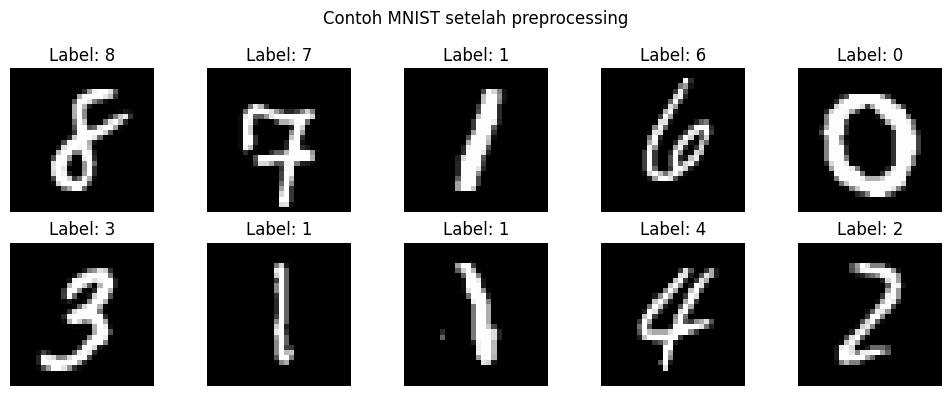

In [7]:
# 5. Tampilkan 10 contoh gambar latihan setelah preprocessing.
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i, :, :, 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis("off")

fig.suptitle("Contoh MNIST setelah preprocessing")
plt.tight_layout()
plt.show()

In [44]:
# 6. Buat PyTorch Dataset.
# Data sebelumnya masih berupa NumPy array dengan bentuk (N, 28, 28, 1).
# PyTorch menggunakan format channel-first, yaitu (N, C, H, W).
# Karena MNIST adalah gambar grayscale, jumlah kanalnya adalah 1.
class MNISTDataset(Dataset):
    def __init__(self, images):
        # Simpan kumpulan gambar yang sudah melalui preprocessing.
        self.images = images

    def __len__(self):
        # Kembalikan jumlah gambar dalam dataset.
        return len(self.images)

    def __getitem__(self, index):
        # Ambil satu gambar berdasarkan indeks.
        image = self.images[index]

        # Ubah NumPy array menjadi PyTorch tensor.
        image = torch.from_numpy(image)

        # Ubah bentuk dari HWC menjadi CHW.
        # (28, 28, 1) -> (1, 28, 28)
        image = image.permute(2, 0, 1)

        return image

In [45]:
# 7. Buat dataset untuk training, validation, dan testing.

train_dataset = MNISTDataset(x_train)
val_dataset = MNISTDataset(x_val)
test_dataset = MNISTDataset(x_test)

print(f"Train      : {len(train_dataset):,} gambar")
print(f"Validasi   : {len(val_dataset):,} gambar")
print(f"Test       : {len(test_dataset):,} gambar")

Train      : 54,000 gambar
Validasi   : 6,000 gambar
Test       : 10,000 gambar


In [46]:
# 8. Periksa satu sample dari PyTorch Dataset.
# Pastikan bentuk, tipe data, dan rentang piksel sudah sesuai dengan kebutuhan model.

sample = train_dataset[0]

print(f"Shape : {sample.shape}")
print(f"Dtype : {sample.dtype}")
print(f"Min   : {sample.min().item():.1f}")
print(f"Max   : {sample.max().item():.1f}")

Shape : torch.Size([1, 28, 28])
Dtype : torch.float32
Min   : 0.0
Max   : 1.0


In [47]:
# 9. Buat DataLoader untuk training, validation, dan testing.
# DataLoader digunakan untuk mengambil data dalam bentuk batch.
# Batch size = 128 berarti model akan menerima maksimal 128 gambar dalam satu batch.

BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    pin_memory=(device.type == "cuda"),
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=(device.type == "cuda"),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=(device.type == "cuda"),
)

print(f"Batch size: {BATCH_SIZE}")

Batch size: 128


In [48]:
# 10. Periksa satu batch dari training DataLoader.
# Bentuk yang diharapkan:
# (batch_size, channel, height, width)
# (128, 1, 28, 28)

images = next(iter(train_loader))

print(f"Shape : {images.shape}")
print(f"Dtype : {images.dtype}")
print(f"Min   : {images.min().item():.1f}")
print(f"Max   : {images.max().item():.1f}")

Shape : torch.Size([128, 1, 28, 28])
Dtype : torch.float32
Min   : 0.0
Max   : 1.0


In [49]:
# 11. Periksa jumlah batch pada setiap DataLoader.
# Jumlah batch digunakan untuk memastikan seluruh data dapat dibaca melalui DataLoader.

print(f"Jumlah batch train      : {len(train_loader)}")
print(f"Jumlah batch validation : {len(val_loader)}")
print(f"Jumlah batch test       : {len(test_loader)}")

Jumlah batch train      : 422
Jumlah batch validation : 47
Jumlah batch test       : 79


In [50]:
# 12. Membuat arsitektur Variational Autoencoder (VAE).
# Model VAE digunakan untuk mempelajari representasi laten dari gambar MNIST
# melalui encoder, reparameterization trick, dan decoder.

import torch
import torch.nn as nn
import torch.nn.functional as F


class VAE(nn.Module):
    """
    Variational Autoencoder (VAE) berbasis MLP untuk dataset MNIST.

    Parameters
    ----------
    hidden_dim : int
        Jumlah neuron pada hidden layer encoder dan decoder.
        Default: 128.

    latent_dim : int
        Dimensi latent space.
        Default: 2.
    """

    def __init__(self, hidden_dim=128, latent_dim=2):
        super().__init__()

        # Memastikan ukuran hidden layer dan latent space valid.
        if hidden_dim <= 0:
            raise ValueError("hidden_dim harus lebih besar dari 0.")

        if latent_dim <= 0:
            raise ValueError("latent_dim harus lebih besar dari 0.")

        self.hidden_dim = hidden_dim
        self.latent_dim = latent_dim

        # Encoder: mengubah gambar 784 piksel menjadi representasi tersembunyi.
        self.encoder_fc = nn.Linear(28 * 28, hidden_dim)

        # Menghasilkan parameter distribusi latent space, yaitu mu dan logvar.
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)

        # Decoder: mengubah latent vector menjadi representasi gambar.
        self.decoder_fc1 = nn.Linear(latent_dim, hidden_dim)
        self.decoder_fc2 = nn.Linear(hidden_dim, 28 * 28)

    def encode(self, x):
        """
        Mengubah gambar menjadi parameter distribusi latent space.

        Input:
            x: [B, 1, 28, 28]

        Output:
            mu:     [B, latent_dim]
            logvar: [B, latent_dim]
        """
        # Meratakan gambar dari [B, 1, 28, 28] menjadi [B, 784].
        x = torch.flatten(x, start_dim=1)

        # Mengekstraksi fitur menggunakan encoder.
        hidden = F.relu(self.encoder_fc(x))

        # Menghasilkan mean dan log-variance distribusi laten.
        mu = self.fc_mu(hidden)
        logvar = self.fc_logvar(hidden)

        return mu, logvar

    def reparameterize(self, mu, logvar):
        """
        Sampling latent vector menggunakan reparameterization trick.

        z = mu + exp(0.5 * logvar) * epsilon
        epsilon ~ N(0, I)
        """
        # Menghitung standar deviasi dari log-variance.
        std = torch.exp(0.5 * logvar)

        # Mengambil sampel acak dari distribusi normal standar.
        epsilon = torch.randn_like(std)

        # Membentuk latent vector menggunakan mean, standar deviasi,
        # dan sampel acak.
        z = mu + std * epsilon

        return z

    def decode(self, z):
        """
        Mengubah latent vector menjadi rekonstruksi gambar.

        Input:
            z: [B, latent_dim]

        Output:
            reconstruction_flat: [B, 784]
        """
        # Memproses latent vector melalui hidden layer decoder.
        hidden = F.relu(self.decoder_fc1(z))

        # Menghasilkan nilai piksel dalam rentang 0 sampai 1.
        reconstruction_flat = torch.sigmoid(
            self.decoder_fc2(hidden)
        )

        return reconstruction_flat

    def forward(self, x):
        """
        Menjalankan keseluruhan proses VAE.

        Input:
            x: [B, 1, 28, 28]

        Output:
            reconstruction: [B, 1, 28, 28]
            mu:             [B, latent_dim]
            logvar:         [B, latent_dim]
        """
        # Memastikan input memiliki bentuk gambar MNIST yang sesuai.
        if x.ndim != 4 or tuple(x.shape[1:]) != (1, 28, 28):
            raise ValueError(
                "Input harus berbentuk [B, 1, 28, 28], "
                f"tetapi menerima {tuple(x.shape)}."
            )

        batch_size = x.shape[0]

        # 1. Encoder: menghasilkan parameter distribusi laten.
        mu, logvar = self.encode(x)

        # 2. Reparameterization: mengambil sampel latent vector.
        z = self.reparameterize(mu, logvar)

        # 3. Decoder: merekonstruksi gambar dari latent vector.
        reconstruction_flat = self.decode(z)

        # 4. Mengembalikan bentuk output menjadi gambar [B, 1, 28, 28].
        reconstruction = reconstruction_flat.reshape(
            batch_size, 1, 28, 28
        )

        return reconstruction, mu, logvar


# Membuat model VAE baseline dengan hidden_dim 128 dan latent_dim 2.
vae_model = VAE(hidden_dim=128, latent_dim=2).to(device)

# Menampilkan struktur arsitektur model VAE.
print(vae_model)


VAE(
  (encoder_fc): Linear(in_features=784, out_features=128, bias=True)
  (fc_mu): Linear(in_features=128, out_features=2, bias=True)
  (fc_logvar): Linear(in_features=128, out_features=2, bias=True)
  (decoder_fc1): Linear(in_features=2, out_features=128, bias=True)
  (decoder_fc2): Linear(in_features=128, out_features=784, bias=True)
)


In [51]:
# 13. Menguji arsitektur VAE menggunakan data dari DataLoader.
# Pengujian dilakukan untuk memastikan bentuk output model sesuai,
# nilai yang dihasilkan valid, dan model dapat memproses batch
# dengan ukuran berbeda sebelum memasuki tahap training.

# Mengambil satu batch dari DataLoader yang sudah tersedia
batch = next(iter(train_loader))

# Mengambil gambar tanpa membuat Dataset atau DataLoader baru
if isinstance(batch, (tuple, list)):
    images = batch[0]

elif isinstance(batch, dict):
    image_key = next(
        (
            key
            for key in ("image", "images", "data", "input", "x")
            if key in batch
        ),
        None,
    )

    if image_key is None:
        raise KeyError(
            "Tidak ditemukan key gambar pada batch. "
            f"Key yang tersedia: {list(batch.keys())}"
        )

    images = batch[image_key]

else:
    images = batch


# Memastikan batch sesuai dengan format input model
if not torch.is_tensor(images):
    raise TypeError("Data gambar harus berupa PyTorch tensor.")

if images.ndim != 4 or tuple(images.shape[1:]) != (1, 28, 28):
    raise ValueError(
        "Bentuk batch harus [B, 1, 28, 28]. "
        f"Bentuk aktual: {tuple(images.shape)}"
    )


# Menggunakan perangkat yang dipilih pada cell awal.
vae_model = vae_model.to(device)
vae_model.eval()

images = images.to(
    device=device,
    dtype=torch.float32,
    non_blocking=(device.type == "cuda"),
)


# Pengujian pertama: satu batch dari train_loader
with torch.no_grad():
    reconstruction, mu, logvar = vae_model(images)

batch_size = images.shape[0]

assert reconstruction.shape == images.shape
assert mu.shape == (batch_size, 2)
assert logvar.shape == (batch_size, 2)

assert torch.isfinite(reconstruction).all()
assert torch.isfinite(mu).all()
assert torch.isfinite(logvar).all()

assert reconstruction.min().item() >= 0.0
assert reconstruction.max().item() <= 1.0

print("=== Pengujian Satu Batch ===")
print("Device:", device)
print("Input gambar       :", tuple(images.shape))
print("Reconstruction     :", tuple(reconstruction.shape))
print("Mu                 :", tuple(mu.shape))
print("Logvar             :", tuple(logvar.shape))
print("Rentang reconstruction:",
      f"{reconstruction.min().item():.4f} - "
      f"{reconstruction.max().item():.4f}")
print("Pengujian batch berhasil.")


# Pengujian kedua: batch dengan ukuran lebih kecil
# Tidak membuat atau mengubah DataLoader.
partial_size = min(7, batch_size)
partial_images = images[:partial_size]

with torch.no_grad():
    partial_reconstruction, partial_mu, partial_logvar = (
        vae_model(partial_images)
    )

assert partial_reconstruction.shape == (
    partial_size, 1, 28, 28
)
assert partial_mu.shape == (partial_size, 2)
assert partial_logvar.shape == (partial_size, 2)

print("\n=== Pengujian Batch Lebih Kecil ===")
print("Input gambar       :", tuple(partial_images.shape))
print("Reconstruction     :", tuple(partial_reconstruction.shape))
print("Mu                 :", tuple(partial_mu.shape))
print("Logvar             :", tuple(partial_logvar.shape))
print("Pengujian batch lebih kecil berhasil.")


=== Pengujian Satu Batch ===
Device: cpu
Input gambar       : (128, 1, 28, 28)
Reconstruction     : (128, 1, 28, 28)
Mu                 : (128, 2)
Logvar             : (128, 2)
Rentang reconstruction: 0.0716 - 0.8981
Pengujian batch berhasil.

=== Pengujian Batch Lebih Kecil ===
Input gambar       : (7, 1, 28, 28)
Reconstruction     : (7, 1, 28, 28)
Mu                 : (7, 2)
Logvar             : (7, 2)
Pengujian batch lebih kecil berhasil.


In [52]:
# 14. Implementasi fungsi loss Variational Autoencoder (VAE).
# Fungsi ini menggabungkan Binary Cross Entropy (BCE) sebagai reconstruction loss
# dan KL Divergence untuk mengatur distribusi laten agar mendekati distribusi
# normal standar. Loss dihitung per gambar, kemudian dirata-ratakan berdasarkan
# jumlah sampel dalam batch. Fungsi ini akan digunakan pada tahap training.

import torch
import torch.nn.functional as F


def vae_loss_function(reconstruction, x, mu, logvar, beta=1.0):
    """
    Menghitung loss Variational Autoencoder (VAE).

    Parameter:
        reconstruction: Gambar hasil rekonstruksi, [B, 1, 28, 28].
        x:              Gambar asli, [B, 1, 28, 28].
        mu:             Mean distribusi laten, [B, latent_dim].
        logvar:         Log variance distribusi laten, [B, latent_dim].
        beta:           Bobot KL Divergence, default 1.0.

    Return:
        total_loss: Rata-rata total loss per gambar dalam batch.
        bce_loss:   Rata-rata reconstruction loss per gambar.
        kl_loss:    Rata-rata KL Divergence per gambar.
    """

    # 1. Validasi bentuk tensor.
    if reconstruction.shape != x.shape:
        raise ValueError(
            "Bentuk reconstruction dan x harus sama. "
            f"Diperoleh {tuple(reconstruction.shape)} dan {tuple(x.shape)}."
        )

    if x.ndim != 4 or tuple(x.shape[1:]) != (1, 28, 28):
        raise ValueError(
            "x harus berbentuk [B, 1, 28, 28]."
        )

    if mu.ndim != 2 or logvar.shape != mu.shape:
        raise ValueError(
            "mu dan logvar harus memiliki bentuk [B, latent_dim] "
            "yang sama."
        )

    if mu.shape[0] != x.shape[0]:
        raise ValueError(
            "Ukuran batch mu dan logvar harus sama dengan batch gambar."
        )

    if beta < 0:
        raise ValueError("beta tidak boleh negatif.")

    # 2. Menghitung BCE untuk setiap piksel, lalu menjumlahkan 784 piksel
    # pada setiap gambar. Hasil akhirnya memiliki bentuk [B].
    bce_per_pixel = F.binary_cross_entropy(
        reconstruction,
        x,
        reduction="none"
    )

    bce_per_image = bce_per_pixel.flatten(start_dim=1).sum(dim=1)

    # 3. Menghitung KL Divergence untuk setiap dimensi laten,
    # lalu menjumlahkannya untuk setiap gambar. Hasilnya berbentuk [B].
    kl_per_dimension = -0.5 * (
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    kl_per_image = kl_per_dimension.sum(dim=1)

    # 4. Menggabungkan BCE dan KL Divergence untuk setiap gambar.
    # Total loss kemudian dirata-ratakan berdasarkan jumlah gambar dalam batch.
    total_per_image = bce_per_image + beta * kl_per_image

    bce_loss = bce_per_image.mean()
    kl_loss = kl_per_image.mean()
    total_loss = total_per_image.mean()

    return total_loss, bce_loss, kl_loss


# 5. Memastikan fungsi loss berhasil didefinisikan.
assert callable(vae_loss_function)

print("Fungsi vae_loss_function berhasil dibuat.")
print("Komponen: BCE + beta * KL Divergence")
print("Beta default:", 1.0)


Fungsi vae_loss_function berhasil dibuat.
Komponen: BCE + beta * KL Divergence
Beta default: 1.0


In [53]:
# 15. Menguji fungsi loss VAE menggunakan satu batch dari train_loader.
# Pengujian memastikan total loss, BCE, dan KL Divergence menghasilkan
# nilai yang valid dan konsisten tanpa melakukan training model.

vae_model.eval()

batch = next(iter(train_loader))

if isinstance(batch, (tuple, list)):
    x_test = batch[0]
elif isinstance(batch, dict):
    image_key = next(
        key for key in ("image", "images", "data", "input", "x")
        if key in batch
    )
    x_test = batch[image_key]
else:
    x_test = batch

x_test = x_test.to(
    device=device, dtype=torch.float32, non_blocking=(device.type == "cuda")
)

with torch.no_grad():
    reconstruction_test, mu_test, logvar_test = vae_model(x_test)

    total_loss_test, bce_test, kl_test = vae_loss_function(
        reconstruction_test,
        x_test,
        mu_test,
        logvar_test
    )

assert total_loss_test.ndim == 0
assert bce_test.ndim == 0
assert kl_test.ndim == 0

assert torch.isfinite(total_loss_test).item()
assert torch.isfinite(bce_test).item()
assert torch.isfinite(kl_test).item()

assert torch.allclose(
    total_loss_test,
    bce_test + kl_test,
    rtol=1e-5,
    atol=1e-6
)

print("\n=== Pemeriksaan VAE Loss ===")
print(f"Batch size       : {x_test.shape[0]}")
print(f"Reconstruction BCE: {bce_test.item():.4f}")
print(f"KL Divergence     : {kl_test.item():.4f}")
print(f"Total VAE Loss    : {total_loss_test.item():.4f}")
print("Pemeriksaan loss berhasil.")



=== Pemeriksaan VAE Loss ===
Batch size       : 128
Reconstruction BCE: 550.2648
KL Divergence     : 0.0274
Total VAE Loss    : 550.2922
Pemeriksaan loss berhasil.


In [54]:
# 16. Menyiapkan konfigurasi training baseline dan optimizer.
# Cell ini menentukan hyperparameter awal, membuat instance VAE baru,
# dan menyiapkan optimizer Adam sebelum proses training dimulai.
# Pemeriksaan dilakukan untuk memastikan konfigurasi model, optimizer,
# fungsi loss, dan DataLoader sudah sesuai.

import torch
import torch.optim as optim
from pathlib import Path

BASELINE_CHECKPOINT_PATH = Path("results/baseline/vae_baseline.pth")


# ============================================================
# 1. Konfigurasi baseline
# ============================================================

HIDDEN_DIM = 128
LATENT_DIM = 2
BATCH_SIZE = 128
LEARNING_RATE = 0.001
BETA = 1.0

# Gunakan perangkat GPU/CPU yang dipilih pada cell awal.


# ============================================================
# 2. Membuat instance model untuk training baseline
# ============================================================

# Menggunakan kelas VAE dari Cell 12.
# Instance baru memastikan training dimulai dari bobot awal
# yang terpisah dari pengujian model sebelumnya.

vae_model = VAE(
    hidden_dim=HIDDEN_DIM,
    latent_dim=LATENT_DIM
).to(device)


# ============================================================
# 3. Menyiapkan optimizer Adam
# ============================================================

# Adam memperbarui parameter model berdasarkan gradien loss.
# Parameter model belum diperbarui sampai training loop dijalankan.

optimizer = optim.Adam(
    vae_model.parameters(),
    lr=LEARNING_RATE
)


# ============================================================
# 4. Pemeriksaan konfigurasi
# ============================================================

# Memastikan instance model menggunakan konfigurasi baseline.
assert vae_model.hidden_dim == HIDDEN_DIM
assert vae_model.latent_dim == LATENT_DIM

# Memastikan seluruh parameter model berada pada perangkat terpilih.
assert all(
    parameter.device.type == device.type
    for parameter in vae_model.parameters()
)

# Memastikan optimizer menggunakan learning rate yang ditentukan.
for param_group in optimizer.param_groups:
    assert param_group["lr"] == LEARNING_RATE

# Memastikan fungsi loss dari Cell 14 tersedia.
assert callable(vae_loss_function)

# Memastikan DataLoader yang sudah ada tetap tersedia.
assert train_loader is not None
assert val_loader is not None
assert test_loader is not None

# Memastikan batch size train_loader sesuai konfigurasi baseline.
assert train_loader.batch_size == BATCH_SIZE, (
    f"Batch size train_loader adalah {train_loader.batch_size}, "
    f"sedangkan konfigurasi baseline adalah {BATCH_SIZE}."
)


# ============================================================
# 5. Menampilkan ringkasan konfigurasi
# ============================================================

print("=== Konfigurasi Training Baseline ===")
print(f"Hidden dimension : {HIDDEN_DIM}")
print(f"Latent dimension : {LATENT_DIM}")
print(f"Batch size       : {BATCH_SIZE}")
print(f"Learning rate    : {LEARNING_RATE}")
print(f"Beta             : {BETA}")
print(f"Optimizer        : {type(optimizer).__name__}")
print(f"Device           : {device}")
print(f"Loss function    : {vae_loss_function.__name__}")

print("\nJumlah parameter model:",
      sum(p.numel() for p in vae_model.parameters()))

print("Jumlah parameter yang dapat dilatih:",
      sum(p.numel() for p in vae_model.parameters()
          if p.requires_grad))

print("\nPemeriksaan konfigurasi berhasil.")


=== Konfigurasi Training Baseline ===
Hidden dimension : 128
Latent dimension : 2
Batch size       : 128
Learning rate    : 0.001
Beta             : 1.0
Optimizer        : Adam
Device           : cpu
Loss function    : vae_loss_function

Jumlah parameter model: 202516
Jumlah parameter yang dapat dilatih: 202516

Pemeriksaan konfigurasi berhasil.


In [55]:
# 17. Fungsi training dan evaluasi VAE
# Menggunakan VAE, vae_loss_function, train_loader, val_loader,
# optimizer, device, dan konfigurasi yang sudah tersedia dari Cell 12–16.
# Fungsi ini dapat digunakan kembali untuk konfigurasi tuning berikutnya.

import torch


def train_one_epoch(
    model,
    data_loader,
    optimizer,
    device,
    beta=1.0,
):
    """Melatih model selama satu epoch dan mengembalikan rata-rata loss."""

    model.train()

    total_loss_sum = 0.0
    total_bce_sum = 0.0
    total_kl_sum = 0.0
    total_samples = 0

    for batch in data_loader:
        # Mendukung batch berbentuk tensor, tuple/list, atau dictionary.
        if isinstance(batch, (tuple, list)):
            images = batch[0]
        elif isinstance(batch, dict):
            if "image" in batch:
                images = batch["image"]
            elif "images" in batch:
                images = batch["images"]
            else:
                raise KeyError(
                    "Batch dictionary harus memiliki key 'image' atau 'images'."
                )
        else:
            images = batch

        images = images.to(device, non_blocking=(device.type == "cuda"))

        # Bersihkan gradien dari langkah sebelumnya.
        optimizer.zero_grad()

        # Forward pass: menghasilkan rekonstruksi, mu, dan logvar.
        reconstruction, mu, logvar = model(images)

        # Hitung total loss, reconstruction loss (BCE), dan KL divergence.
        loss, bce_loss, kl_loss = vae_loss_function(
            reconstruction,
            images,
            mu,
            logvar,
            beta=beta,
        )

        # Backpropagation dan pembaruan parameter model.
        loss.backward()
        optimizer.step()

        # Akumulasi loss berbobot jumlah sampel agar rata-rata epoch akurat.
        batch_size_actual = images.size(0)
        total_loss_sum += loss.item() * batch_size_actual
        total_bce_sum += bce_loss.item() * batch_size_actual
        total_kl_sum += kl_loss.item() * batch_size_actual
        total_samples += batch_size_actual

    if total_samples == 0:
        raise ValueError("DataLoader training tidak memiliki sampel.")

    return {
        "loss": total_loss_sum / total_samples,
        "bce": total_bce_sum / total_samples,
        "kl": total_kl_sum / total_samples,
    }


def evaluate_vae(
    model,
    data_loader,
    device,
    beta=1.0,
):
    """Mengevaluasi VAE tanpa memperbarui parameter model."""

    model.eval()

    total_loss_sum = 0.0
    total_bce_sum = 0.0
    total_kl_sum = 0.0
    total_samples = 0

    with torch.no_grad():
        for batch in data_loader:
            # Ambil citra dari format batch yang didukung.
            if isinstance(batch, (tuple, list)):
                images = batch[0]
            elif isinstance(batch, dict):
                if "image" in batch:
                    images = batch["image"]
                elif "images" in batch:
                    images = batch["images"]
                else:
                    raise KeyError(
                        "Batch dictionary harus memiliki key 'image' atau 'images'."
                    )
            else:
                images = batch

            images = images.to(device, non_blocking=(device.type == "cuda"))

            # Forward pass tanpa menghitung gradien.
            reconstruction, mu, logvar = model(images)

            loss, bce_loss, kl_loss = vae_loss_function(
                reconstruction,
                images,
                mu,
                logvar,
                beta=beta,
            )

            batch_size_actual = images.size(0)
            total_loss_sum += loss.item() * batch_size_actual
            total_bce_sum += bce_loss.item() * batch_size_actual
            total_kl_sum += kl_loss.item() * batch_size_actual
            total_samples += batch_size_actual

    if total_samples == 0:
        raise ValueError("DataLoader validation tidak memiliki sampel.")

    return {
        "loss": total_loss_sum / total_samples,
        "bce": total_bce_sum / total_samples,
        "kl": total_kl_sum / total_samples,
    }


# Pengujian training juga dilewati jika checkpoint baseline tersedia.
if BASELINE_CHECKPOINT_PATH.is_file():
    print("Checkpoint baseline tersedia; pengujian training satu epoch dilewati.")
else:
    train_metrics = train_one_epoch(
        model=vae_model,
        data_loader=train_loader,
        optimizer=optimizer,
        device=device,
        beta=BETA,
    )

    # Evaluasi validation loss setelah satu epoch training.
    val_metrics = evaluate_vae(
        model=vae_model,
        data_loader=val_loader,
        device=device,
        beta=BETA,
    )

    # Pastikan hasil evaluasi berupa angka yang valid.
    for metric_name, metric_value in train_metrics.items():
        assert torch.isfinite(torch.tensor(metric_value)).item(), (
            f"Training metric {metric_name} tidak valid: {metric_value}"
        )

    for metric_name, metric_value in val_metrics.items():
        assert torch.isfinite(torch.tensor(metric_value)).item(), (
            f"Validation metric {metric_name} tidak valid: {metric_value}"
        )

    # Tampilkan ringkasan hasil epoch pertama.
    print("=== Baseline VAE: Epoch 1 ===")
    print(f"Training loss      : {train_metrics['loss']:.4f}")
    print(f"Training BCE       : {train_metrics['bce']:.4f}")
    print(f"Training KL        : {train_metrics['kl']:.4f}")
    print(f"Validation loss    : {val_metrics['loss']:.4f}")
    print(f"Validation BCE     : {val_metrics['bce']:.4f}")
    print(f"Validation KL      : {val_metrics['kl']:.4f}")
    print(f"Training samples   : {len(train_loader.dataset)}")
    print(f"Validation samples : {len(val_loader.dataset)}")
    print("\nTraining satu epoch dan evaluasi validation berhasil.")


Checkpoint baseline tersedia; pengujian training satu epoch dilewati.


In [56]:
# 18. Muat baseline tersimpan, atau jalankan training jika belum tersedia.
import json
import pandas as pd

# Periksa ulang agar cell aman dijalankan kembali setelah penyimpanan.
baseline_loaded_from_checkpoint = BASELINE_CHECKPOINT_PATH.is_file()

if baseline_loaded_from_checkpoint:
    baseline_checkpoint = torch.load(
        BASELINE_CHECKPOINT_PATH, map_location=device, weights_only=True,
    )
    baseline_config = baseline_checkpoint["config"]
    baseline_model = VAE(
        hidden_dim=baseline_config["hidden_dim"],
        latent_dim=baseline_config["latent_dim"],
    ).to(device)
    baseline_model.load_state_dict(baseline_checkpoint["model_state_dict"])
    baseline_model.eval()
    BASELINE_SEED = baseline_config["seed"]
    NUM_EPOCHS = baseline_config["num_epochs"]

    # Riwayat bersifat opsional untuk pemuatan model.
    history_path = BASELINE_CHECKPOINT_PATH.with_name("vae_baseline_history.json")
    baseline_history = {}
    if history_path.is_file():
        with history_path.open(encoding="utf-8") as file:
            baseline_history = json.load(file)
    baseline_results = pd.DataFrame(baseline_history)

    print(f"Baseline dimuat dari {BASELINE_CHECKPOINT_PATH}; training dilewati.")
    if not baseline_results.empty:
        print(baseline_results.round(4).to_string(index=False))
else:
    # 18. Training baseline VAE selama tepat 50 epoch
    # Model dimulai dari bobot baru, bukan bobot hasil pengujian Cell 17.
    # Dataset, DataLoader, arsitektur VAE, dan fungsi loss tetap menggunakan
    # komponen yang sudah dibuat pada Cell 1–17.

    import torch
    import torch.optim as optim
    import pandas as pd
    import random
    import numpy as np

    # 1. Tetapkan seed agar inisialisasi dan eksperimen lebih mudah direproduksi.
    # Seed tidak menjamin hasil identik pada semua lingkungan/perangkat.
    BASELINE_SEED = 42

    random.seed(BASELINE_SEED)
    np.random.seed(BASELINE_SEED)
    torch.manual_seed(BASELINE_SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(BASELINE_SEED)

    # 2. Inisialisasi model baru dengan konfigurasi baseline yang sama.
    # Model ini tidak menggunakan bobot hasil pengujian satu epoch pada Cell 17.
    baseline_model = VAE(
        hidden_dim=HIDDEN_DIM,
        latent_dim=LATENT_DIM,
    ).to(device)

    # Buat optimizer baru yang terhubung ke parameter model baseline baru.
    baseline_optimizer = optim.Adam(
        baseline_model.parameters(),
        lr=LEARNING_RATE,
    )

    # 3. Siapkan tempat penyimpanan metrik setiap epoch.
    # Dictionary ini dapat diubah menjadi DataFrame untuk tabel dan grafik.
    baseline_history = {
        "epoch": [],
        "train_loss": [],
        "train_bce": [],
        "train_kl": [],
        "val_loss": [],
        "val_bce": [],
        "val_kl": [],
    }

    # 4. Jalankan tepat 50 epoch training dan evaluasi validation.
    NUM_EPOCHS = 50

    for epoch in range(1, NUM_EPOCHS + 1):
        # Training hanya menggunakan train_loader.
        train_metrics = train_one_epoch(
            model=baseline_model,
            data_loader=train_loader,
            optimizer=baseline_optimizer,
            device=device,
            beta=BETA,
        )

        # Evaluasi menggunakan val_loader, bukan test_loader.
        val_metrics = evaluate_vae(
            model=baseline_model,
            data_loader=val_loader,
            device=device,
            beta=BETA,
        )

        # Simpan semua metrik untuk analisis, tabel, dan grafik selanjutnya.
        baseline_history["epoch"].append(epoch)
        baseline_history["train_loss"].append(train_metrics["loss"])
        baseline_history["train_bce"].append(train_metrics["bce"])
        baseline_history["train_kl"].append(train_metrics["kl"])
        baseline_history["val_loss"].append(val_metrics["loss"])
        baseline_history["val_bce"].append(val_metrics["bce"])
        baseline_history["val_kl"].append(val_metrics["kl"])

        # Tampilkan hasil epoch saat ini.
        print(
            f"Epoch [{epoch:02d}/{NUM_EPOCHS}] | "
            f"Train Loss: {train_metrics['loss']:.4f} | "
            f"Train BCE: {train_metrics['bce']:.4f} | "
            f"Train KL: {train_metrics['kl']:.4f} | "
            f"Val Loss: {val_metrics['loss']:.4f} | "
            f"Val BCE: {val_metrics['bce']:.4f} | "
            f"Val KL: {val_metrics['kl']:.4f}"
        )

    # 5. Ubah riwayat training menjadi tabel.
    baseline_results = pd.DataFrame(baseline_history)

    # 6. Periksa kelengkapan dan validitas hasil.
    assert len(baseline_results) == NUM_EPOCHS, (
        "Jumlah epoch pada hasil tidak sesuai."
    )

    assert baseline_results["epoch"].tolist() == list(
        range(1, NUM_EPOCHS + 1)
    ), "Urutan epoch tidak sesuai."

    metric_columns = [
        "train_loss", "train_bce", "train_kl",
        "val_loss", "val_bce", "val_kl",
    ]

    assert np.isfinite(
        baseline_results[metric_columns].to_numpy()
    ).all(), "Ada metrik yang bukan angka finite."

    # Periksa konsistensi total loss dengan BCE + beta * KL.
    assert np.allclose(
        baseline_results["train_loss"],
        baseline_results["train_bce"] + BETA * baseline_results["train_kl"],
        rtol=1e-4,
        atol=1e-3,
    ), "Training loss tidak konsisten dengan BCE + beta * KL."

    assert np.allclose(
        baseline_results["val_loss"],
        baseline_results["val_bce"] + BETA * baseline_results["val_kl"],
        rtol=1e-4,
        atol=1e-3,
    ), "Validation loss tidak konsisten dengan BCE + beta * KL."

    # 7. Tampilkan tabel hasil lengkap dan konfigurasi baseline.
    print("\n=== Hasil Training Baseline VAE ===")
    print(baseline_results.round(4).to_string(index=False))

    print("\n=== Konfigurasi Baseline ===")
    print(f"Seed          : {BASELINE_SEED}")
    print(f"Hidden dim    : {HIDDEN_DIM}")
    print(f"Latent dim    : {LATENT_DIM}")
    print(f"Batch size    : {BATCH_SIZE}")
    print(f"Learning rate : {LEARNING_RATE}")
    print(f"Beta          : {BETA}")
    print(f"Epoch         : {NUM_EPOCHS}")
    print(f"Device        : {device}")

    print("\nTraining baseline 50 epoch selesai.")
    print("Seluruh metrik berhasil diperiksa.")


Baseline dimuat dari results\baseline\vae_baseline.pth; training dilewati.
 epoch  train_loss  train_bce  train_kl  val_loss  val_bce  val_kl
     1    211.9128   203.6882    8.2247  182.9717 177.2476  5.7242
     2    178.2237   172.7372    5.4865  174.4600 169.0207  5.4393
     3    172.7302   167.5943    5.1358  170.5448 165.1730  5.3717
     4    169.2970   164.1835    5.1135  167.3952 162.0070  5.3882
     5    166.7953   161.5979    5.1974  165.4359 160.1077  5.3282
     6    164.8246   159.5348    5.2898  163.7656 158.3976  5.3681
     7    163.4455   158.1035    5.3420  162.7432 157.2955  5.4477
     8    162.4042   157.0125    5.3916  161.7184 156.4517  5.2667
     9    161.5597   156.1531    5.4066  161.0227 155.4038  5.6189
    10    160.8787   155.4395    5.4392  160.3414 154.8891  5.4523
    11    160.2723   154.8111    5.4612  159.9024 154.3286  5.5738
    12    159.7497   154.2580    5.4917  159.5264 154.0744  5.4520
    13    159.2530   153.7167    5.5363  159.1034 153.

In [57]:
# 19. Simpan hanya hasil baseline yang baru dilatih.
if baseline_loaded_from_checkpoint:
    print("Baseline memakai checkpoint tersimpan; artefak baseline tidak ditulis ulang.")
else:
    # 19. Menyimpan model baseline dan seluruh hasil eksperimen
    # Menggunakan baseline_model, baseline_optimizer, baseline_history,
    # baseline_results, dan konfigurasi yang sudah tersedia dari Cell 16–18.
    # Tidak menjalankan training ulang.

    from pathlib import Path
    import json
    import torch
    import pandas as pd

    # 1. Buat folder output jika belum tersedia.
    # Path relatif terhadap working directory notebook saat ini.
    output_dir = Path("results") / "baseline"
    output_dir.mkdir(parents=True, exist_ok=True)

    # 2. Simpan konfigurasi eksperimen baseline.
    baseline_config = {
        "experiment_name": "vae_baseline",
        "model_name": "VAE",
        "hidden_dim": HIDDEN_DIM,
        "latent_dim": LATENT_DIM,
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "beta": BETA,
        "num_epochs": NUM_EPOCHS,
        "seed": BASELINE_SEED,
        "optimizer": type(baseline_optimizer).__name__,
        "loss_function": "vae_loss_function",
        "device_used": str(device),
        "training_samples": len(train_loader.dataset),
        "validation_samples": len(val_loader.dataset),
        "validation_source": "val_loader",
    }

    # 3. Ambil metrik epoch terakhir dengan benar.
    # baseline_history berisi list metrik dari epoch 1 sampai epoch 50.
    final_train_metrics = {
        key: float(value[-1])
        for key, value in baseline_history.items()
        if key.startswith("train_")
    }

    final_validation_metrics = {
        key: float(value[-1])
        for key, value in baseline_history.items()
        if key.startswith("val_")
    }

    # Pastikan metrik epoch terakhir tersedia dan valid.
    assert final_train_metrics, "Metrik training tidak ditemukan."
    assert final_validation_metrics, "Metrik validation tidak ditemukan."

    assert all(
        torch.isfinite(torch.tensor(value)).item()
        for value in final_train_metrics.values()
    ), "Terdapat metrik training yang tidak valid."

    assert all(
        torch.isfinite(torch.tensor(value)).item()
        for value in final_validation_metrics.values()
    ), "Terdapat metrik validation yang tidak valid."

    # 4. Simpan checkpoint: bobot model, konfigurasi, dan metrik akhir.
    checkpoint_path = output_dir / "vae_baseline.pth"

    torch.save(
        {
            "model_state_dict": baseline_model.state_dict(),
            "config": baseline_config,
            "final_train_metrics": final_train_metrics,
            "final_validation_metrics": final_validation_metrics,
        },
        checkpoint_path,
    )

    # 5. Simpan konfigurasi baseline dalam format JSON.
    config_path = output_dir / "vae_baseline_config.json"

    with open(config_path, "w", encoding="utf-8") as file:
        json.dump(baseline_config, file, indent=4, ensure_ascii=False)

    # 6. Simpan riwayat metrik lengkap dari seluruh epoch ke JSON.
    # Konversi nilai menjadi tipe Python standar agar kompatibel dengan JSON.
    history_json = {
        key: [
            int(value) if key == "epoch" else float(value)
            for value in values
        ]
        for key, values in baseline_history.items()
    }

    history_path = output_dir / "vae_baseline_history.json"

    with open(history_path, "w", encoding="utf-8") as file:
        json.dump(history_json, file, indent=4, ensure_ascii=False)

    # 7. Simpan tabel hasil baseline ke CSV.
    csv_path = output_dir / "vae_baseline_results.csv"
    baseline_results.to_csv(csv_path, index=False)

    # 8. Periksa keberadaan dan ukuran semua file yang dibuat.
    saved_files = [
        checkpoint_path,
        config_path,
        history_path,
        csv_path,
    ]

    for file_path in saved_files:
        assert file_path.is_file(), f"File tidak ditemukan: {file_path}"
        assert file_path.stat().st_size > 0, f"File kosong: {file_path}"

    # 9. Baca kembali checkpoint untuk memverifikasi isinya.
    # weights_only=True didukung oleh versi PyTorch modern,
    # termasuk versi yang mendukung format checkpoint berisi tensor dan tipe dasar.
    try:
        saved_checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True,
        )
    except TypeError:
        # Fallback untuk versi PyTorch lama yang belum memiliki argumen weights_only.
        saved_checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
        )

    assert "model_state_dict" in saved_checkpoint
    assert "config" in saved_checkpoint
    assert "final_train_metrics" in saved_checkpoint
    assert "final_validation_metrics" in saved_checkpoint

    assert saved_checkpoint["config"]["num_epochs"] == 50
    assert saved_checkpoint["config"]["hidden_dim"] == HIDDEN_DIM
    assert saved_checkpoint["config"]["latent_dim"] == LATENT_DIM

    # 10. Validasi CSV: harus berisi tepat 50 epoch.
    saved_results = pd.read_csv(csv_path)

    assert len(saved_results) == 50, (
        f"CSV seharusnya berisi 50 baris, tetapi ditemukan {len(saved_results)}."
    )

    assert "epoch" in saved_results.columns
    assert saved_results["epoch"].tolist() == list(range(1, 51))

    # 11. Pastikan riwayat JSON juga memuat 50 epoch.
    with open(history_path, "r", encoding="utf-8") as file:
        saved_history = json.load(file)

    assert len(saved_history["epoch"]) == 50
    assert saved_history["epoch"] == list(range(1, 51))

    # 12. Tampilkan lokasi dan ringkasan hasil penyimpanan.
    print("=== Penyimpanan Baseline Berhasil ===")
    print(f"Folder output: {output_dir.resolve()}")

    print("\nFile yang berhasil disimpan:")
    for file_path in saved_files:
        print(f"- {file_path.resolve()}")
        print(f"  Ukuran: {file_path.stat().st_size:,} bytes")

    print("\nJumlah epoch dalam CSV:", len(saved_results))
    print("Jumlah epoch dalam JSON:", len(saved_history["epoch"]))

    print("\nMetrik training epoch terakhir:")
    for name, value in final_train_metrics.items():
        print(f"- {name}: {value:.4f}")

    print("\nMetrik validation epoch terakhir:")
    for name, value in final_validation_metrics.items():
        print(f"- {name}: {value:.4f}")

    print("\nSemua pemeriksaan penyimpanan berhasil.")


Baseline memakai checkpoint tersimpan; artefak baseline tidak ditulis ulang.


In [58]:
# 20. Persiapan Grid Search

from itertools import product
from pathlib import Path
import json
import csv
import math

# Daftar hyperparameter
GRID_PARAMS = {
    "hidden_dim": [128, 256, 512],
    "latent_dim": [2, 4, 8, 16],
    "batch_size": [64, 128],
    "learning_rate": [0.001, 0.005, 0.0001],
}

GRID_EPOCHS = 10
GRID_SEED = 42
GRID_BETA = 1.0

# Folder khusus Grid Search
GRID_SEARCH_DIR = Path("results/grid_search")
GRID_SEARCH_DIR.mkdir(parents=True, exist_ok=True)

# Gunakan pilihan terbaik tersimpan. Jika metadata belum ada, baca ringkasan.
BEST_COMBINATION_PATH = GRID_SEARCH_DIR / "best_combination.json"
saved_best_combination = None
if BEST_COMBINATION_PATH.is_file():
    with BEST_COMBINATION_PATH.open(encoding="utf-8") as file:
        saved_best_combination = json.load(file)
else:
    summary_path = GRID_SEARCH_DIR / "grid_search_summary.csv"
    if summary_path.is_file():
        with summary_path.open(encoding="utf-8", newline="") as file:
            completed_results = [
                row for row in csv.DictReader(file)
                if row["status"] == "completed"
                and row["best_val_loss"]
                and math.isfinite(float(row["best_val_loss"]))
            ]
        if completed_results:
            best_result = min(
                completed_results, key=lambda row: float(row["best_val_loss"])
            )
            best_config_dir = GRID_SEARCH_DIR / best_result["config_id"]
            with (best_config_dir / "config.json").open(encoding="utf-8") as file:
                best_config = json.load(file)
            saved_best_combination = {
                "config_id": best_result["config_id"],
                "config": best_config,
                "best_val_loss": float(best_result["best_val_loss"]),
                "best_val_bce": float(best_result["best_val_bce"]),
                "best_val_kl": float(best_result["best_val_kl"]),
                "best_val_epoch": int(best_result["best_val_epoch"]),
                "checkpoint_path": (best_config_dir / "best_model.pth").as_posix(),
            }

grid_loaded_from_checkpoint = (
    saved_best_combination is not None
    and Path(saved_best_combination["checkpoint_path"]).is_file()
)
if grid_loaded_from_checkpoint:
    print("Checkpoint terbaik tersedia; hyperparameter tuning dilewati.")

# Membentuk seluruh kombinasi secara otomatis
param_names = list(GRID_PARAMS.keys())

GRID_COMBINATIONS = [
    dict(zip(param_names, values))
    for values in product(
        *(GRID_PARAMS[name] for name in param_names)
    )
]

# Menyimpan konfigurasi grid
grid_config = {
    "parameters": GRID_PARAMS,
    "epochs": GRID_EPOCHS,
    "seed": GRID_SEED,
    "beta": GRID_BETA,
    "total_combinations": len(GRID_COMBINATIONS),
}

if not grid_loaded_from_checkpoint:
    with open(
        GRID_SEARCH_DIR / "grid_config.json",
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(grid_config, f, indent=4)

print("=" * 45)
print("PERSIAPAN GRID SEARCH")
print("=" * 45)
print(f"Hidden dimensions : {GRID_PARAMS['hidden_dim']}")
print(f"Latent dimensions : {GRID_PARAMS['latent_dim']}")
print(f"Batch sizes       : {GRID_PARAMS['batch_size']}")
print(f"Learning rates    : {GRID_PARAMS['learning_rate']}")
print(f"Epoch per model   : {GRID_EPOCHS}")
print(f"Total kombinasi   : {len(GRID_COMBINATIONS)}")
print(f"Folder hasil      : {GRID_SEARCH_DIR}")

print("\nContoh 5 kombinasi pertama:")
for i, config in enumerate(GRID_COMBINATIONS[:5], start=1):
    print(f"{i}. {config}")


print(f"\nPemeriksaan berhasil: terdapat {len(GRID_COMBINATIONS)} kombinasi.")


Checkpoint terbaik tersedia; hyperparameter tuning dilewati.
PERSIAPAN GRID SEARCH
Hidden dimensions : [128, 256, 512]
Latent dimensions : [2, 4, 8, 16]
Batch sizes       : [64, 128]
Learning rates    : [0.001, 0.005, 0.0001]
Epoch per model   : 10
Total kombinasi   : 72
Folder hasil      : results\grid_search

Contoh 5 kombinasi pertama:
1. {'hidden_dim': 128, 'latent_dim': 2, 'batch_size': 64, 'learning_rate': 0.001}
2. {'hidden_dim': 128, 'latent_dim': 2, 'batch_size': 64, 'learning_rate': 0.005}
3. {'hidden_dim': 128, 'latent_dim': 2, 'batch_size': 64, 'learning_rate': 0.0001}
4. {'hidden_dim': 128, 'latent_dim': 2, 'batch_size': 128, 'learning_rate': 0.001}
5. {'hidden_dim': 128, 'latent_dim': 2, 'batch_size': 128, 'learning_rate': 0.005}

Pemeriksaan berhasil: terdapat 72 kombinasi.


In [59]:
# 21. Menjalankan Grid Search untuk VAE

import json
import time
import random
import copy
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from torch.utils.data import DataLoader

# --------------------------------------------------
# 1. Persiapan folder dan file hasil
# --------------------------------------------------

GRID_SEARCH_DIR = Path("results/grid_search")
GRID_SEARCH_DIR.mkdir(parents=True, exist_ok=True)

SUMMARY_PATH = GRID_SEARCH_DIR / "grid_search_summary.csv"

RESULT_COLUMNS = [
    "config_id",
    "hidden_dim",
    "latent_dim",
    "batch_size",
    "learning_rate",
    "epochs",
    "best_val_loss",
    "best_val_bce",
    "best_val_kl",
    "best_val_epoch",
    "final_train_loss",
    "duration_seconds",
    "status",
    "error",
]

if SUMMARY_PATH.exists():
    summary_df = pd.read_csv(SUMMARY_PATH)

    # Pastikan kolom sesuai dengan format yang digunakan
    for col in RESULT_COLUMNS:
        if col not in summary_df.columns:
            summary_df[col] = np.nan
else:
    summary_df = pd.DataFrame(columns=RESULT_COLUMNS)


def save_summary_row(result):
    """Simpan atau perbarui hasil satu kombinasi."""
    global summary_df

    config_id = result["config_id"]

    summary_df = summary_df[
        summary_df["config_id"] != config_id
    ]

    summary_df = pd.concat(
        [summary_df, pd.DataFrame([result])],
        ignore_index=True,
    )

    summary_df.to_csv(SUMMARY_PATH, index=False)


# --------------------------------------------------
# 2. Siapkan DataLoader berdasarkan batch size
# --------------------------------------------------

def make_grid_loader(dataset, batch_size, shuffle, seed):
    generator = torch.Generator()
    generator.manual_seed(seed)

    # Pertahankan pengaturan worker dari DataLoader awal
    original_loader = (
        train_loader if shuffle else val_loader
    )

    kwargs = {
        "dataset": dataset,
        "batch_size": batch_size,
        "shuffle": shuffle,
        "num_workers": original_loader.num_workers,
        "pin_memory": original_loader.pin_memory,
        "drop_last": False,
        "generator": generator if shuffle else None,
    }

    if original_loader.num_workers > 0:
        kwargs["persistent_workers"] = (
            original_loader.persistent_workers
        )

        if original_loader.prefetch_factor is not None:
            kwargs["prefetch_factor"] = (
                original_loader.prefetch_factor
            )

    return DataLoader(**kwargs)


# --------------------------------------------------
# 3. Jalankan satu kombinasi hyperparameter
# --------------------------------------------------

def run_grid_combination(config, combination_number):
    config_id = f"GS_{combination_number:03d}"
    output_dir = GRID_SEARCH_DIR / config_id
    output_dir.mkdir(parents=True, exist_ok=True)

    config = dict(config)

    config["epochs"] = GRID_EPOCHS
    config["beta"] = GRID_BETA
    config["seed"] = GRID_SEED

    config_path = output_dir / "config.json"

    with open(config_path, "w", encoding="utf-8") as f:
        json.dump(config, f, indent=4)

    # Set seed agar inisialisasi model dapat direproduksi
    seed = GRID_SEED
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    train_loader_grid = make_grid_loader(
        train_loader.dataset,
        config["batch_size"],
        shuffle=True,
        seed=seed,
    )

    val_loader_grid = make_grid_loader(
        val_loader.dataset,
        config["batch_size"],
        shuffle=False,
        seed=seed,
    )

    model = VAE(
        config["hidden_dim"],
        config["latent_dim"],
    ).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=config["learning_rate"],
    )

    history = []
    best_val_loss = float("inf")
    best_val_bce = float("nan")
    best_val_kl = float("nan")
    best_val_epoch = 0
    final_train_loss = float("nan")

    start_time = time.time()
    status = "completed"
    error_message = ""

    print("\n" + "=" * 65)
    print(
        f"{config_id} | "
        f"hidden={config['hidden_dim']}, "
        f"latent={config['latent_dim']}, "
        f"batch={config['batch_size']}, "
        f"lr={config['learning_rate']}"
    )
    print("=" * 65)

    try:
        for epoch in range(1, GRID_EPOCHS + 1):

            train_metrics = train_one_epoch(
                model,
                train_loader_grid,
                optimizer,
                device,
                beta=GRID_BETA,
            )

            val_metrics = evaluate_vae(
                model,
                val_loader_grid,
                device,
                beta=GRID_BETA,
            )

            metrics = {
                "epoch": epoch,
                "train_loss": float(train_metrics["loss"]),
                "train_bce": float(train_metrics["bce"]),
                "train_kl": float(train_metrics["kl"]),
                "val_loss": float(val_metrics["loss"]),
                "val_bce": float(val_metrics["bce"]),
                "val_kl": float(val_metrics["kl"]),
            }

            # Hentikan kombinasi jika hasil tidak valid
            if not all(
                np.isfinite(value)
                for key, value in metrics.items()
                if key != "epoch"
            ):
                raise ValueError(
                    f"Loss NaN/Inf pada epoch {epoch}"
                )

            history.append(metrics)
            final_train_loss = metrics["train_loss"]

            if metrics["val_loss"] < best_val_loss:
                best_val_loss = metrics["val_loss"]
                best_val_bce = metrics["val_bce"]
                best_val_kl = metrics["val_kl"]
                best_val_epoch = epoch

                torch.save(
                    {
                        "model_state_dict": copy.deepcopy(
                            model.state_dict()
                        ),
                        "config": config,
                        "best_val_loss": best_val_loss,
                        "best_val_epoch": best_val_epoch,
                    },
                    output_dir / "best_model.pth",
                )

            # Simpan progres setelah setiap epoch
            with open(
                output_dir / "history.json",
                "w",
                encoding="utf-8",
            ) as f:
                json.dump(history, f, indent=4)

            pd.DataFrame(history).to_csv(
                output_dir / "epoch_history.csv",
                index=False,
            )

            print(
                f"Epoch {epoch:02d}/{GRID_EPOCHS} | "
                f"Train Loss: {metrics['train_loss']:.4f} | "
                f"Val Loss: {metrics['val_loss']:.4f} | "
                f"BCE: {metrics['val_bce']:.4f} | "
                f"KL: {metrics['val_kl']:.4f}"
            )

    except Exception as exc:
        status = "failed"
        error_message = f"{type(exc).__name__}: {exc}"
        print(f"❌ {config_id} gagal: {error_message}")

    duration = time.time() - start_time

    result = {
        "config_id": config_id,
        "hidden_dim": config["hidden_dim"],
        "latent_dim": config["latent_dim"],
        "batch_size": config["batch_size"],
        "learning_rate": config["learning_rate"],
        "epochs": GRID_EPOCHS,
        "best_val_loss": (
            best_val_loss if np.isfinite(best_val_loss)
            else np.nan
        ),
        "best_val_bce": (
            best_val_bce if np.isfinite(best_val_bce)
            else np.nan
        ),
        "best_val_kl": (
            best_val_kl if np.isfinite(best_val_kl)
            else np.nan
        ),
        "best_val_epoch": best_val_epoch,
        "final_train_loss": (
            final_train_loss
            if np.isfinite(final_train_loss)
            else np.nan
        ),
        "duration_seconds": round(duration, 2),
        "status": status,
        "error": error_message,
    }

    save_summary_row(result)

    print(
        f"Status: {status} | "
        f"Best validation loss: {result['best_val_loss']}"
    )

    return result


# --------------------------------------------------
# 4. Jalankan seluruh kombinasi
# --------------------------------------------------

completed_ids = set(
    config_id for config_id in summary_df.loc[
        summary_df["status"] == "completed",
        "config_id",
    ].dropna().astype(str)
    if (GRID_SEARCH_DIR / config_id / "best_model.pth").is_file()
)

remaining = [
    (i, config)
    for i, config in enumerate(
        GRID_COMBINATIONS, start=1
    )
    if f"GS_{i:03d}" not in completed_ids
]

print("=" * 65)
print("MEMULAI GRID SEARCH")
print(f"Total kombinasi       : {len(GRID_COMBINATIONS)}")
print(f"Kombinasi sudah selesai: {len(completed_ids)}")
print(f"Kombinasi tersisa     : {len(remaining)}")
print(f"Perangkat             : {device}")
print(f"Folder hasil          : {GRID_SEARCH_DIR}")
print("=" * 65)

if grid_loaded_from_checkpoint:
    print(f"Tuning dilewati; memakai {saved_best_combination['checkpoint_path']}.")
else:
    for position, (number, config) in enumerate(remaining, start=1):
        print(
            f"\nProgres kombinasi: {position}/{len(remaining)}"
        )

        run_grid_combination(config, number)

# --------------------------------------------------
# 5. Ringkasan hasil
# --------------------------------------------------

if SUMMARY_PATH.is_file():
    summary_df = pd.read_csv(SUMMARY_PATH)

successful = summary_df[
    (summary_df["status"] == "completed")
    & summary_df["best_val_loss"].notna()
].copy()

successful = successful.sort_values(
    "best_val_loss",
    ascending=True,
)

print("\n" + "=" * 65)
print("GRID SEARCH SELESAI")
print("=" * 65)
print(f"Total tercatat : {len(summary_df)}")
print(f"Berhasil       : {(summary_df['status'] == 'completed').sum()}")
print(f"Gagal          : {(summary_df['status'] == 'failed').sum()}")

if not successful.empty:
    print("\n5 kombinasi terbaik berdasarkan validation loss:")
    print(
        successful[
            [
                "config_id",
                "hidden_dim",
                "latent_dim",
                "batch_size",
                "learning_rate",
                "best_val_loss",
                "best_val_epoch",
            ]
        ].head(5).to_string(index=False)
    )

    print("\nKombinasi terbaik:")
    print(successful.iloc[0].to_string())

# Simpan 5 kombinasi terbaik, terurut berdasarkan validation loss.
top5_combinations = (
    successful.loc[np.isfinite(successful["best_val_loss"])]
    .sort_values(["best_val_loss", "config_id"])
    .head(5)
    .reset_index(drop=True)
)

top5_combinations.insert(
    0, "peringkat", range(1, len(top5_combinations) + 1)
)

top5_combinations.to_csv(
    GRID_SEARCH_DIR / "top5_combinations.csv",
    index=False,
)

print(f"\nFile ringkasan: {SUMMARY_PATH}")


MEMULAI GRID SEARCH
Total kombinasi       : 72
Kombinasi sudah selesai: 72
Kombinasi tersisa     : 0
Perangkat             : cpu
Folder hasil          : results\grid_search
Tuning dilewati; memakai results/grid_search/GS_067/best_model.pth.

GRID SEARCH SELESAI
Total tercatat : 72
Berhasil       : 72
Gagal          : 0

5 kombinasi terbaik berdasarkan validation loss:
config_id  hidden_dim  latent_dim  batch_size  learning_rate  best_val_loss  best_val_epoch
   GS_067         512          16          64          0.001     106.333612              10
   GS_070         512          16         128          0.001     106.650783              10
   GS_071         512          16         128          0.005     107.082864               9
   GS_043         256          16          64          0.001     108.065473              10
   GS_047         256          16         128          0.005     108.451699               9

Kombinasi terbaik:
config_id               GS_067
hidden_dim                

In [60]:
# Baca dan cetak 5 kombinasi terbaik yang sudah disimpan.
top5_results = pd.read_csv(
    GRID_SEARCH_DIR / "top5_combinations.csv"
).sort_values("peringkat")

print(
    top5_results[
        [
            "peringkat",
            "config_id",
            "hidden_dim",
            "latent_dim",
            "batch_size",
            "learning_rate",
            "best_val_loss",
            "best_val_epoch",
        ]
    ].to_string(index=False)
)

 peringkat config_id  hidden_dim  latent_dim  batch_size  learning_rate  best_val_loss  best_val_epoch
         1    GS_067         512          16          64          0.001     106.333612              10
         2    GS_070         512          16         128          0.001     106.650783              10
         3    GS_071         512          16         128          0.005     107.082864               9
         4    GS_043         256          16          64          0.001     108.065473              10
         5    GS_047         256          16         128          0.005     108.451699               9


In [24]:
MAX_EPOCHS = 50
PATIENCE = 5

RETRAIN_DIR = Path("results/retrain_top5")
RETRAIN_DIR.mkdir(parents=True, exist_ok=True)


selected_configs = (
    top5_results
    .sort_values("peringkat")
    .head(5)
    .reset_index(drop=True)
)

if (
    len(selected_configs) != 5
    or selected_configs["config_id"].nunique() != 5
):
    raise ValueError("Diperlukan 5 kombinasi terbaik yang berbeda.")

retrain_results = []

for _, row in selected_configs.iterrows():
    config_id = str(row["config_id"])
    output_dir = RETRAIN_DIR / config_id
    output_dir.mkdir(parents=True, exist_ok=True)

    # Baca konfigurasi asli hasil Grid Search.
    config_path = (
        Path("results/grid_search") / config_id / "config.json"
    )

    with config_path.open(encoding="utf-8") as file:
        config = json.load(file)

    config.update({
        "hidden_dim": int(row["hidden_dim"]),
        "latent_dim": int(row["latent_dim"]),
        "batch_size": int(row["batch_size"]),
        "learning_rate": float(row["learning_rate"]),
        "epochs": MAX_EPOCHS,
        "early_stopping_patience": PATIENCE,
        "source_config_id": config_id,
    })

    seed = int(config["seed"])
    beta = float(config["beta"])

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Menggunakan helper DataLoader dari Cell 21.
    retrain_train_loader = make_grid_loader(
        train_loader.dataset,
        batch_size=config["batch_size"],
        shuffle=True,
        seed=seed,
    )

    retrain_val_loader = make_grid_loader(
        val_loader.dataset,
        batch_size=config["batch_size"],
        shuffle=False,
        seed=seed,
    )

    # Model dan optimizer baru: training dimulai dari bobot awal.
    model = VAE(
        hidden_dim=config["hidden_dim"],
        latent_dim=config["latent_dim"],
    ).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=config["learning_rate"],
    )

    checkpoint_path = output_dir / "best_model.pth"
    best_val_loss = float("inf")
    best_epoch = 0
    best_metrics = None
    epochs_without_improvement = 0
    history = []
    start_time = time.perf_counter()

    print(f"\n{'=' * 65}")
    print(f"Training ulang {config_id}")
    print(json.dumps(config, indent=4))
    print("=" * 65)

    for epoch in range(1, MAX_EPOCHS + 1):
        train_metrics = train_one_epoch(
            model=model,
            data_loader=retrain_train_loader,
            optimizer=optimizer,
            device=device,
            beta=beta,
        )

        val_metrics = evaluate_vae(
            model=model,
            data_loader=retrain_val_loader,
            device=device,
            beta=beta,
        )

        epoch_metrics = {
            "epoch": epoch,
            "train_loss": float(train_metrics["loss"]),
            "train_bce": float(train_metrics["bce"]),
            "train_kl": float(train_metrics["kl"]),
            "val_loss": float(val_metrics["loss"]),
            "val_bce": float(val_metrics["bce"]),
            "val_kl": float(val_metrics["kl"]),
        }

        if not all(np.isfinite(v) for v in epoch_metrics.values()):
            raise ValueError(
                f"{config_id}: metrik NaN/Inf pada epoch {epoch}."
            )

        history.append(epoch_metrics)

        if epoch_metrics["val_loss"] < best_val_loss:
            best_val_loss = epoch_metrics["val_loss"]
            best_epoch = epoch
            best_metrics = epoch_metrics.copy()
            epochs_without_improvement = 0

            # Simpan bobot pada epoch terbaik, bukan epoch terakhir.
            torch.save(
                {
                    "model_state_dict": model.state_dict(),
                    "config": config.copy(),
                    "best_val_loss": best_val_loss,
                    "best_val_epoch": best_epoch,
                    "best_val_bce": best_metrics["val_bce"],
                    "best_val_kl": best_metrics["val_kl"],
                },
                checkpoint_path,
            )
        else:
            epochs_without_improvement += 1

        # Simpan progres setiap epoch.
        pd.DataFrame(history).to_csv(
            output_dir / "history.csv",
            index=False,
        )

        print(
            f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
            f"Train: {epoch_metrics['train_loss']:.4f} | "
            f"Val: {epoch_metrics['val_loss']:.4f} | "
            f"Best: {best_val_loss:.4f} | "
            f"Patience: {epochs_without_improvement}/{PATIENCE}"
        )

        if epochs_without_improvement >= PATIENCE:
            print(
                f"Early stopping pada epoch {epoch}. "
                f"Epoch terbaik: {best_epoch}."
            )
            break

    config["epochs_trained"] = len(history)
    config["best_val_epoch"] = best_epoch

    # Lengkapi metadata checkpoint dengan durasi training aktual.
    saved_checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True,
    )
    saved_checkpoint["config"] = config.copy()
    torch.save(saved_checkpoint, checkpoint_path)

    with (output_dir / "config.json").open(
        "w", encoding="utf-8"
    ) as file:
        json.dump(config, file, indent=4, allow_nan=False)

    retrain_results.append({
        "config_id": config_id,
        "hidden_dim": config["hidden_dim"],
        "latent_dim": config["latent_dim"],
        "batch_size": config["batch_size"],
        "learning_rate": config["learning_rate"],
        "grid_val_loss": float(row["best_val_loss"]),
        "best_val_loss": best_val_loss,
        "best_val_bce": best_metrics["val_bce"],
        "best_val_kl": best_metrics["val_kl"],
        "best_epoch": best_epoch,
        "epochs_trained": len(history),
        "duration_seconds": round(
            time.perf_counter() - start_time, 2
        ),
        "checkpoint_path": checkpoint_path.as_posix(),
    })

    # Simpan hasil setiap model agar progres tidak hilang.
    pd.DataFrame(retrain_results).to_csv(
        RETRAIN_DIR / "retrain_summary.csv",
        index=False,
    )

    del model, optimizer, saved_checkpoint


Training ulang GS_067
{
    "hidden_dim": 512,
    "latent_dim": 16,
    "batch_size": 64,
    "learning_rate": 0.001,
    "epochs": 50,
    "beta": 1.0,
    "seed": 42,
    "early_stopping_patience": 5,
    "source_config_id": "GS_067"
}
Epoch 01/50 | Train: 146.6846 | Val: 119.9963 | Best: 119.9963 | Patience: 0/5
Epoch 02/50 | Train: 116.1026 | Val: 113.4172 | Best: 113.4172 | Patience: 0/5
Epoch 03/50 | Train: 111.8656 | Val: 110.8615 | Best: 110.8615 | Patience: 0/5
Epoch 04/50 | Train: 109.9070 | Val: 109.3305 | Best: 109.3305 | Patience: 0/5
Epoch 05/50 | Train: 108.6599 | Val: 108.4245 | Best: 108.4245 | Patience: 0/5
Epoch 06/50 | Train: 107.8403 | Val: 107.8288 | Best: 107.8288 | Patience: 0/5
Epoch 07/50 | Train: 107.1314 | Val: 107.1220 | Best: 107.1220 | Patience: 0/5
Epoch 08/50 | Train: 106.5952 | Val: 106.6932 | Best: 106.6932 | Patience: 0/5
Epoch 09/50 | Train: 106.1360 | Val: 106.4683 | Best: 106.4683 | Patience: 0/5
Epoch 10/50 | Train: 105.7167 | Val: 106.3336 | B

In [25]:
# Pilih model berdasarkan validation loss terendah.
comparison = (
    pd.read_csv(RETRAIN_DIR / "retrain_summary.csv")
    .sort_values(["best_val_loss", "config_id"])
    .reset_index(drop=True)
)

comparison.insert(
    0, "peringkat", range(1, len(comparison) + 1)
)

comparison["penurunan_val_loss"] = (
    comparison["grid_val_loss"] - comparison["best_val_loss"]
)

comparison.to_csv(
    RETRAIN_DIR / "comparison.csv",
    index=False,
)

print("=== Perbandingan Hasil Training Ulang ===")
print(
    comparison[
        [
            "peringkat",
            "config_id",
            "hidden_dim",
            "latent_dim",
            "batch_size",
            "learning_rate",
            "grid_val_loss",
            "best_val_loss",
            "penurunan_val_loss",
            "best_val_bce",
            "best_val_kl",
            "best_epoch",
            "epochs_trained",
        ]
    ].to_string(
        index=False,
        float_format=lambda value: f"{value:.6f}",
    )
)

# Muat checkpoint pemenang.
winner = comparison.iloc[0]

best_checkpoint = torch.load(
    Path(winner["checkpoint_path"]),
    map_location="cpu",
    weights_only=True,
)

BEST_MODEL_DIR = Path("results/best_model")
BEST_MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Simpan model terbaik dan konfigurasi yang sesuai.
torch.save(
    best_checkpoint,
    BEST_MODEL_DIR / "best_model.pth",
)

with (BEST_MODEL_DIR / "config.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(
        best_checkpoint["config"],
        file,
        indent=4,
        allow_nan=False,
    )

comparison.to_csv(
    BEST_MODEL_DIR / "comparison.csv",
    index=False,
)

# Siapkan model terbaik untuk evaluasi atau rekonstruksi.
best_config = best_checkpoint["config"]

best_model = VAE(
    hidden_dim=best_config["hidden_dim"],
    latent_dim=best_config["latent_dim"],
).to(device)

best_model.load_state_dict(
    best_checkpoint["model_state_dict"]
)
best_model.eval()

print(f"\nModel terbaik: {winner['config_id']}")
print(f"Validation loss: {winner['best_val_loss']:.6f}")
print(f"Epoch terbaik: {int(winner['best_epoch'])}")
print(f"Checkpoint: {BEST_MODEL_DIR / 'best_model.pth'}")
print(f"Konfigurasi: {BEST_MODEL_DIR / 'config.json'}")

=== Perbandingan Hasil Training Ulang ===
 peringkat config_id  hidden_dim  latent_dim  batch_size  learning_rate  grid_val_loss  best_val_loss  penurunan_val_loss  best_val_bce  best_val_kl  best_epoch  epochs_trained
         1    GS_067         512          16          64       0.001000     106.333612     101.941903            4.391709     78.561290    23.380613          50              50
         2    GS_070         512          16         128       0.001000     106.650783     102.282318            4.368465     78.227038    24.055281          50              50
         3    GS_043         256          16          64       0.001000     108.065473     104.197562            3.867911     80.350608    23.846955          46              50
         4    GS_071         512          16         128       0.005000     107.082864     105.151740            1.931125     82.050640    23.101099          31              36
         5    GS_047         256          16         128       0.005000  

In [61]:
# Load Checkpoint Baseline dan GS_067

import json
import csv
from pathlib import Path
import torch

# Pastikan file penting tersedia
paths = {
    "Baseline checkpoint": "results/baseline/vae_baseline.pth",
    "Baseline config": "results/baseline/vae_baseline_config.json",
    "GS_067 checkpoint": "results/best_model/best_model.pth",
    "GS_067 config": "results/best_model/config.json",
    "Retraining comparison": "results/best_model/comparison.csv",
    "Grid search summary": "results/grid_search/grid_search_summary.csv",
    "Best combination": "results/grid_search/best_combination.json",
}

for name, path in paths.items():
    assert Path(path).is_file(), f"File tidak ditemukan: {path}"

# Baca konfigurasi
with open(paths["Baseline config"], encoding="utf-8") as f:
    baseline_config = json.load(f)

with open(paths["GS_067 config"], encoding="utf-8") as f:
    config = json.load(f)

assert config["source_config_id"] == "GS_067"

# Ambil metadata hasil retraining GS_067
with open(paths["Retraining comparison"], encoding="utf-8-sig", newline="") as f:
    rows = list(csv.DictReader(f))

result = next((r for r in rows if r["config_id"] == "GS_067"), None)
assert result is not None, "GS_067 tidak ditemukan di comparison.csv"

metadata = {
    "Model terbaik": result["config_id"],
    "Hidden dim": config["hidden_dim"],
    "Latent dim": config["latent_dim"],
    "Batch size": config["batch_size"],
    "Learning rate": config["learning_rate"],
    "Grid validation loss": float(result["grid_val_loss"]),
    "Best validation loss": float(result["best_val_loss"]),
    "Penurunan validation loss": float(result["penurunan_val_loss"]),
    "Best validation BCE": float(result["best_val_bce"]),
    "Best validation KL": float(result["best_val_kl"]),
    "Best epoch": int(result["best_epoch"]),
    "Epochs trained": int(result["epochs_trained"]),
    "Checkpoint": paths["GS_067 checkpoint"],
    "Konfigurasi": paths["GS_067 config"],
}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Buat model, muat bobot, dan aktifkan evaluasi
def load_vae(model_config, checkpoint_path):
    model = VAE(
        hidden_dim=model_config["hidden_dim"],
        latent_dim=model_config["latent_dim"],
    ).to(device)

    weights = torch.load(
        checkpoint_path, map_location=device, weights_only=True
    )
    model.load_state_dict(
        weights.get("model_state_dict", weights)
    )
    model.eval()
    return model

vae_baseline = load_vae(
    baseline_config, paths["Baseline checkpoint"]
)
vae_best = load_vae(config, paths["GS_067 checkpoint"])

models = {"Baseline": vae_baseline, "GS_067": vae_best}
configs = {"Baseline": baseline_config, "GS_067": config}

for name, model in models.items():
    print(f"\n{name}")
    print("Hidden dim:", configs[name]["hidden_dim"])
    print("Latent dim:", configs[name]["latent_dim"])
    print("Eval mode:", not model.training)
    print("Jumlah parameter:", sum(p.numel() for p in model.parameters()))

print("\n=== Metadata Retraining GS_067 ===")
for key, value in metadata.items():
    print(f"{key}: {value}")

print("\nSemua file tersedia dan kedua model berhasil dimuat.")
print("Device:", device)


Baseline
Hidden dim: 128
Latent dim: 2
Eval mode: True
Jumlah parameter: 202516

GS_067
Hidden dim: 512
Latent dim: 16
Eval mode: True
Jumlah parameter: 829232

=== Metadata Retraining GS_067 ===
Model terbaik: GS_067
Hidden dim: 512
Latent dim: 16
Batch size: 64
Learning rate: 0.001
Grid validation loss: 106.3336123046875
Best validation loss: 101.9419028523763
Penurunan validation loss: 4.391709452311204
Best validation BCE: 78.56129005940755
Best validation KL: 23.380613204956056
Best epoch: 50
Epochs trained: 50
Checkpoint: results/best_model/best_model.pth
Konfigurasi: results/best_model/config.json

Semua file tersedia dan kedua model berhasil dimuat.
Device: cpu


In [62]:
# Uji Rekonstruksi dan Loss

import torch
import torch.nn.functional as F

# Ambil satu batch gambar MNIST dari validation loader.
batch = next(iter(val_loader))
images = batch if torch.is_tensor(batch) else next(
    x for x in batch
    if torch.is_tensor(x) and x.ndim == 4
    and tuple(x.shape[1:]) == (1, 28, 28)
)
images = images.to(device=device, dtype=torch.float32)

# Pastikan nilai piksel gambar berada pada rentang 0–1 dan tampilkan dimensinya.
assert images.min() >= 0 and images.max() <= 1
print("Shape gambar asli:", tuple(images.shape))


# Uji rekonstruksi dan hitung loss untuk satu model VAE.
def test_vae(name, model):
    with torch.no_grad():
        reconstruction, mu, logvar = model(images)

        bce = F.binary_cross_entropy(
            reconstruction, images, reduction="sum"
        )
        kl = -0.5 * torch.sum(
            1 + logvar - mu.pow(2) - logvar.exp()
        )
        total = bce + configs[name].get("beta", 1.0) * kl

    # Pastikan hasil rekonstruksi sesuai dimensi input dan loss bernilai valid.
    assert reconstruction.shape == images.shape
    assert torch.isfinite(reconstruction).all()
    assert torch.isfinite(total)

    # Tampilkan dimensi rekonstruksi dan nilai setiap komponen loss.
    print(f"\n{name}")
    print("Shape rekonstruksi:", tuple(reconstruction.shape))
    print(f"BCE Loss:        {bce.item():.4f}")
    print(f"KL Divergence:   {kl.item():.4f}")
    print(f"Total Loss:      {total.item():.4f}")
    print(f"Loss per gambar: {total.item() / len(images):.4f}")
    print("Eval mode:", not model.training)

    return reconstruction


# Jalankan pengujian pada model Baseline dan GS_067.
reconstruction_baseline = test_vae("Baseline", vae_baseline)
reconstruction_best = test_vae("GS_067", vae_best)

print("\nPengujian kedua model berhasil.")

Shape gambar asli: (128, 1, 28, 28)

Baseline
Shape rekonstruksi: (128, 1, 28, 28)
BCE Loss:        18203.2461
KL Divergence:   809.7645
Total Loss:      19013.0098
Loss per gambar: 148.5391
Eval mode: True

GS_067
Shape rekonstruksi: (128, 1, 28, 28)
BCE Loss:        9804.8535
KL Divergence:   2974.7454
Total Loss:      12779.5986
Loss per gambar: 99.8406
Eval mode: True

Pengujian kedua model berhasil.


## A. Analisis Training dan Tuning

Bagian ini mengkaji proses pelatihan model dan hasil penyetelan *hyperparameter* berdasarkan artefak eksperimen yang telah tersimpan, sehingga tidak diperlukan pelatihan ulang. Model terbaik diperoleh melalui tiga tahap:

1. **Baseline**: VAE dengan konfigurasi awal dilatih selama 50 epoch sebagai pembanding.
2. **Grid search**: 72 kombinasi *hyperparameter* masing-masing dilatih selama 10 epoch, lalu diurutkan berdasarkan validation loss terbaik.
3. **Training ulang**: lima kombinasi terbaik dilatih ulang hingga maksimal 50 epoch dengan *early stopping* (patience 5). Kombinasi dengan validation loss terendah dipilih sebagai model terbaik.

Data yang digunakan:

| File | Isi |
|---|---|
| `results/baseline/vae_baseline_history.json` | Riwayat *loss* baseline selama 50 epoch |
| `results/baseline/vae_baseline_config.json` | Konfigurasi baseline |
| `results/best_model/config.json` | Konfigurasi dan epoch terbaik model terpilih |
| `results/retrain_top5/GS_067/history.csv` | Riwayat *loss* model terbaik selama training ulang |
| `results/grid_search/grid_search_summary.csv` | Ringkasan hasil 72 kombinasi grid search |
| `results/grid_search/best_combination.json` | Konfigurasi terbaik pada tahap grid search |

Model yang dibandingkan:

| Model | Hidden dimension | Latent dimension | Batch size | Learning rate | Epoch training | Bobot yang digunakan |
|---|---:|---:|---:|---:|---:|---|
| Baseline | 128 | 2 | 128 | 0,001 | 50 | Epoch 50 |
| GS_067 | 512 | 16 | 64 | 0,001 | 50 | Epoch 50 |

### A.1. Perbandingan Total Loss Baseline dan Model Terbaik

Subbagian ini menilai apakah model belajar secara stabil dan apakah terdapat indikasi *overfitting*. Dua besaran yang dibandingkan adalah:

- **Training loss**: rata-rata *loss* pada 54.000 gambar data latih, dihitung selama satu epoch berlangsung.
- **Validation loss**: rata-rata *loss* pada 6.000 gambar data validasi yang tidak digunakan untuk memperbarui bobot. Nilai ini menjadi dasar pemilihan *checkpoint* dan konfigurasi terbaik.

Nilai *loss* dinyatakan sebagai rata-rata per gambar, yaitu jumlah *loss* atas 784 piksel setiap gambar yang dirata-ratakan terhadap seluruh gambar. Pola grafik dibaca dengan pedoman berikut:

| Pola | Interpretasi |
|---|---|
| Training dan validation loss sama-sama menurun | Model terus mempelajari pola data |
| Training loss menurun, validation loss terus meningkat | Indikasi *overfitting* |
| Loss hampir tidak berubah | Model mendekati konvergen atau mengalami keterbatasan belajar |
| Loss naik-turun secara tajam | Proses pelatihan kurang stabil |

Pada setiap grafik, epoch yang bobotnya digunakan untuk evaluasi ditandai dengan bintang. Kedua grafik menggunakan skala sumbu-y yang berbeda karena rentang *loss* kedua model tidak sama.

Baseline   : 50 epoch, bobot epoch 50
GS_067     : 50 epoch, bobot epoch 50


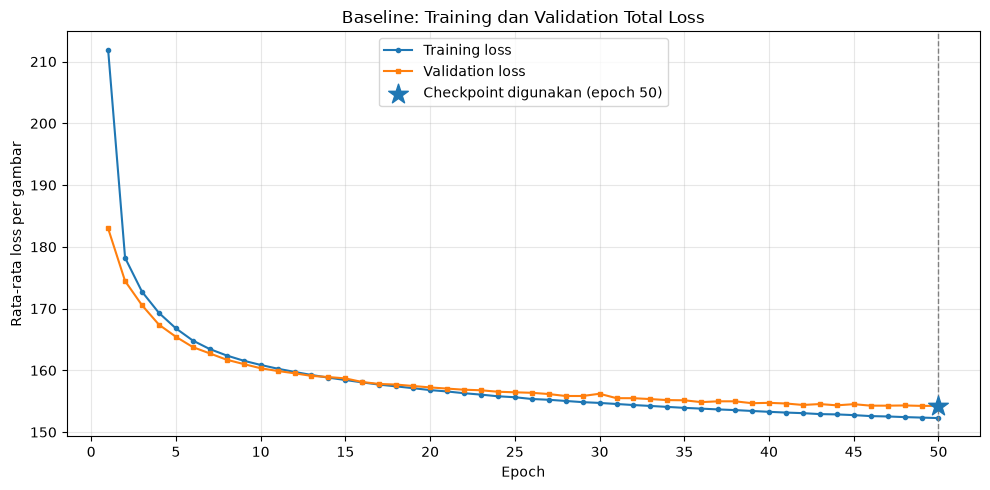

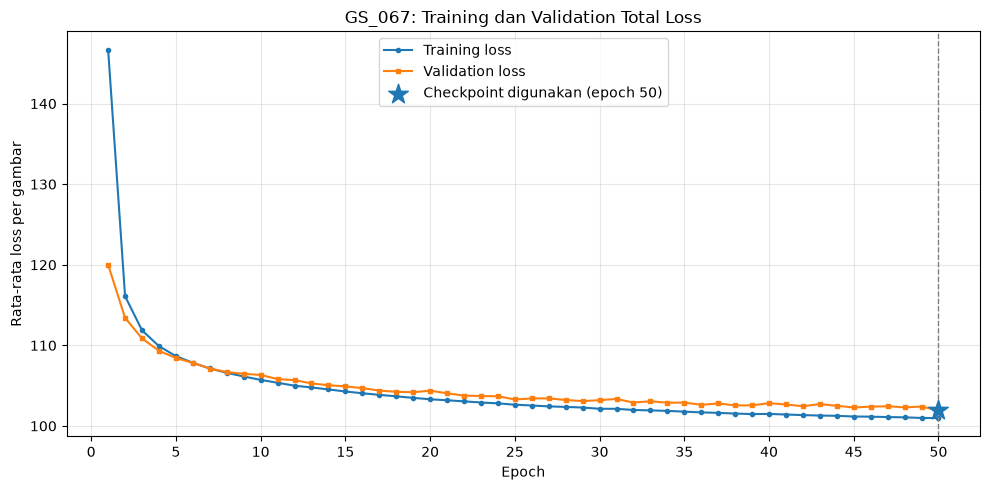

In [63]:
# Grafik Total Loss Baseline dan Model Terbaik

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Folder penyimpanan grafik dan tabel hasil analisis
FIGURE_DIR = Path("results/figures")
EVAL_DIR = Path("results/evaluation")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
EVAL_DIR.mkdir(parents=True, exist_ok=True)

# Konfigurasi baseline dan model terbaik hasil training ulang
with open("results/baseline/vae_baseline_config.json", encoding="utf-8") as f:
    baseline_config_json = json.load(f)

with open("results/best_model/config.json", encoding="utf-8") as f:
    best_model_config = json.load(f)

# ID dan epoch checkpoint diambil dari file, bukan ditulis manual
BEST_ID = best_model_config["source_config_id"]
BEST_EPOCH = int(best_model_config["best_val_epoch"])
BASELINE_EPOCH = int(baseline_config_json["num_epochs"])  # baseline menyimpan bobot epoch terakhir

# Memuat riwayat training yang sudah tersimpan
with open("results/baseline/vae_baseline_history.json", encoding="utf-8") as f:
    baseline_history_df = pd.DataFrame(json.load(f))

best_history_df = pd.read_csv(f"results/retrain_top5/{BEST_ID}/history.csv")

# Memastikan jumlah epoch sesuai konfigurasi
assert len(baseline_history_df) == BASELINE_EPOCH
assert len(best_history_df) == int(best_model_config["epochs_trained"])

print(f"Baseline   : {len(baseline_history_df)} epoch, bobot epoch {BASELINE_EPOCH}")
print(f"{BEST_ID:11s}: {len(best_history_df)} epoch, bobot epoch {BEST_EPOCH}")


def plot_total_loss(history, model_name, best_epoch=None, save_path=None):
    """Menampilkan training dan validation loss setiap epoch."""
    plt.figure(figsize=(10, 5))

    plt.plot(history["epoch"], history["train_loss"],
             marker="o", markersize=3, label="Training loss")
    plt.plot(history["epoch"], history["val_loss"],
             marker="s", markersize=3, label="Validation loss")

    # Tandai checkpoint yang digunakan
    if best_epoch is not None:
        best_loss = history.loc[history["epoch"] == best_epoch, "val_loss"].iloc[0]
        plt.axvline(best_epoch, color="gray", linestyle="--", linewidth=1)
        plt.scatter([best_epoch], [best_loss], marker="*", s=220, zorder=5,
                    label=f"Checkpoint digunakan (epoch {best_epoch})")

    plt.title(f"{model_name}: Training dan Validation Total Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Rata-rata loss per gambar")
    plt.xticks(range(0, len(history) + 1, 5))
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    # Simpan grafik agar dapat digunakan pada laporan
    if save_path is not None:
        plt.savefig(save_path, dpi=150)
    plt.show()


plot_total_loss(baseline_history_df, "Baseline", best_epoch=BASELINE_EPOCH,
                save_path=FIGURE_DIR / "total_loss_baseline.png")
plot_total_loss(best_history_df, BEST_ID, best_epoch=BEST_EPOCH,
                save_path=FIGURE_DIR / "total_loss_best_model.png")

In [64]:
# Tabel Loss pada Epoch Terpilih
# Menampilkan nilai asli dari riwayat, bukan perkiraan dari grafik.

metrics = ["train_loss", "val_loss", "train_bce", "val_bce", "train_kl", "val_kl"]
selected_epochs = [1, 5, 10, 20, 30, 40, 50]

for name, history in [("Baseline", baseline_history_df), (BEST_ID, best_history_df)]:
    print(f"\n=== {name}: Loss pada Epoch Terpilih ===")
    display(
        history.loc[history["epoch"].isin(selected_epochs), ["epoch"] + metrics]
        .round(4)
        .reset_index(drop=True)
    )


=== Baseline: Loss pada Epoch Terpilih ===


,epoch,train_loss,val_loss,train_bce,val_bce,train_kl,val_kl
0,1,211.9128,182.9717,203.6882,177.2476,8.2247,5.7242
1,5,166.7953,165.4359,161.5979,160.1077,5.1974,5.3282
2,10,160.8787,160.3414,155.4395,154.8891,5.4392,5.4523
3,20,156.8058,157.2399,151.1247,151.5505,5.6811,5.6894
4,30,154.7268,156.2132,148.8932,150.4322,5.8336,5.7810
5,40,153.2860,154.7421,147.3595,148.8089,5.9265,5.9332
6,50,152.2734,154.2543,146.2611,148.1673,6.0123,6.0870



=== GS_067: Loss pada Epoch Terpilih ===


,epoch,train_loss,val_loss,train_bce,val_bce,train_kl,val_kl
0,1,146.6846,119.9963,129.7286,98.4399,16.9560,21.5564
1,5,108.6599,108.4245,85.5889,85.2581,23.0710,23.1663
2,10,105.7167,106.3336,82.2962,82.2592,23.4205,24.0744
3,20,103.3121,104.3698,79.7004,79.3847,23.6117,24.9851
4,30,102.1292,103.1950,78.4625,80.0028,23.6667,23.1922
5,40,101.4925,102.8207,77.8169,78.6943,23.6756,24.1264
6,50,100.9763,101.9419,77.2989,78.5613,23.6774,23.3806


In [65]:
# Epoch dengan Validation Loss Terendah dan Selisih Validation - Training

for name, history in [("Baseline", baseline_history_df), (BEST_ID, best_history_df)]:
    best_row = history.loc[history["val_loss"].idxmin()]
    gap = history["val_loss"] - history["train_loss"]

    print(f"\n=== {name} ===")
    print(f"Epoch val loss terendah : {int(best_row['epoch'])}")
    print(f"Training loss           : {best_row['train_loss']:.4f}")
    print(f"Validation loss         : {best_row['val_loss']:.4f}")
    print(f"Validation BCE          : {best_row['val_bce']:.4f}")
    print(f"Validation KL           : {best_row['val_kl']:.4f}")
    print(f"Selisih val - train (10 epoch terakhir): "
          f"{gap.tail(10).min():.2f} sampai {gap.tail(10).max():.2f}")


=== Baseline ===
Epoch val loss terendah : 49
Training loss           : 152.3532
Validation loss         : 154.2487
Validation BCE          : 148.2038
Validation KL           : 6.0449
Selisih val - train (10 epoch terakhir): 1.33 sampai 1.98

=== GS_067 ===
Epoch val loss terendah : 50
Training loss           : 100.9763
Validation loss         : 101.9419
Validation BCE          : 78.5613
Validation KL           : 23.3806
Selisih val - train (10 epoch terakhir): 0.97 sampai 1.43


### Analisis Training dan Validation Loss

Pada baseline, training loss menurun dari 211,91 pada epoch 1 menjadi 152,27 pada epoch 50 (turun 28,1%), sedangkan validation loss menurun dari 182,97 menjadi 154,25 (turun 15,7%). Penurunan terbesar terjadi pada 10 epoch pertama (182,97 → 160,34). Setelah itu laju penurunannya melambat: dari epoch 10 hingga 50, validation loss hanya turun 6,09, dan pada 10 epoch terakhir hanya 0,49. Validation loss terendah dicapai pada epoch 49 (154,249), hampir sama dengan epoch 50 (154,254), sehingga bobot epoch terakhir yang digunakan tetap representatif. Hingga epoch 13, validation loss lebih rendah daripada training loss karena training loss merupakan rata-rata selama satu epoch ketika bobot masih terus diperbarui. Mulai epoch 14, validation loss sedikit lebih tinggi, dan selisihnya bertambah perlahan hingga 1,33–1,98 pada 10 epoch terakhir. Selisih ini masih kecil dan validation loss tidak menunjukkan tren naik, sehingga belum terdapat indikasi *overfitting* yang signifikan.

Pada GS_067, training loss menurun dari 146,68 menjadi 100,98 (turun 31,2%), sedangkan validation loss menurun dari 120,00 menjadi 101,94 (turun 15,0%). Validation loss turun cepat pada 10 epoch pertama (120,00 → 106,33), lalu terus menurun secara perlahan dengan fluktuasi kecil hingga 101,94 pada epoch 50. Nilai terendah tercapai tepat pada epoch terakhir, sehingga *early stopping* tidak pernah terpicu. Hal ini menunjukkan bahwa model masih mengalami perbaikan di akhir training, meskipun kecil (0,35 dalam lima epoch terakhir). Selisih validation dan training loss pada 10 epoch terakhir berada pada kisaran 0,97–1,43, sehingga belum menunjukkan *overfitting* yang signifikan.

Kedua model dilatih dengan jumlah epoch dan learning rate yang sama (50 epoch, 0,001), sehingga perbandingannya lebih adil. Validation loss GS_067 pada epoch 50 (101,94) lebih rendah 52,31 atau 33,9% daripada baseline (154,25). Bahkan validation loss GS_067 pada epoch pertama (120,00) sudah lebih rendah daripada baseline di akhir training. Meskipun demikian, kedua model masih berbeda pada tiga *hyperparameter*, yaitu hidden dimension (128 vs 512), latent dimension (2 vs 16), dan batch size (128 vs 64). Pengaruh masing-masing dianalisis melalui perbandingan terkontrol pada bagian A.3.

### A.2. Komponen BCE dan KL

Fungsi *loss* VAE terdiri atas dua komponen yang dijumlahkan:

$$\mathcal{L} = \text{BCE} + \beta \cdot D_{KL}$$

dengan $\beta = 1$ pada kedua model.

**Binary Cross Entropy (BCE)** atau *reconstruction loss* mengukur perbedaan antara gambar asli $x$ dan gambar hasil rekonstruksi $\hat{x}$ pada setiap piksel:

$$\text{BCE} = -\sum_{i=1}^{784} \left[ x_i \log \hat{x}_i + (1 - x_i) \log (1 - \hat{x}_i) \right]$$

Semakin kecil nilai BCE, semakin mirip hasil rekonstruksi dengan gambar asli.

**Kullback-Leibler Divergence (KL)** mengukur seberapa jauh distribusi laten hasil encoder, $\mathcal{N}(\mu, \sigma^2)$, menyimpang dari distribusi normal standar $\mathcal{N}(0, I)$:

$$D_{KL} = -\frac{1}{2} \sum_{j=1}^{d} \left( 1 + \log \sigma_j^2 - \mu_j^2 - \sigma_j^2 \right)$$

dengan $d$ adalah *latent dimension*. Komponen ini berfungsi sebagai regularisasi agar ruang laten tetap teratur sehingga dapat digunakan untuk membangkitkan gambar baru. Nilai KL cenderung meningkat ketika encoder menyimpan lebih banyak informasi tentang gambar di ruang laten.

Kedua komponen saling tarik-menarik: rekonstruksi yang lebih detail umumnya membutuhkan informasi laten yang lebih banyak, yang berarti KL lebih besar. Oleh karena itu, grafik berikut menampilkan BCE dan KL pada panel terpisah. Pada setiap panel, baseline dan GS_067 ditampilkan bersama sehingga kedua model dapat dibandingkan secara langsung. Setiap garis memiliki warna berbeda, dan garis putus-putus menandai data validasi.

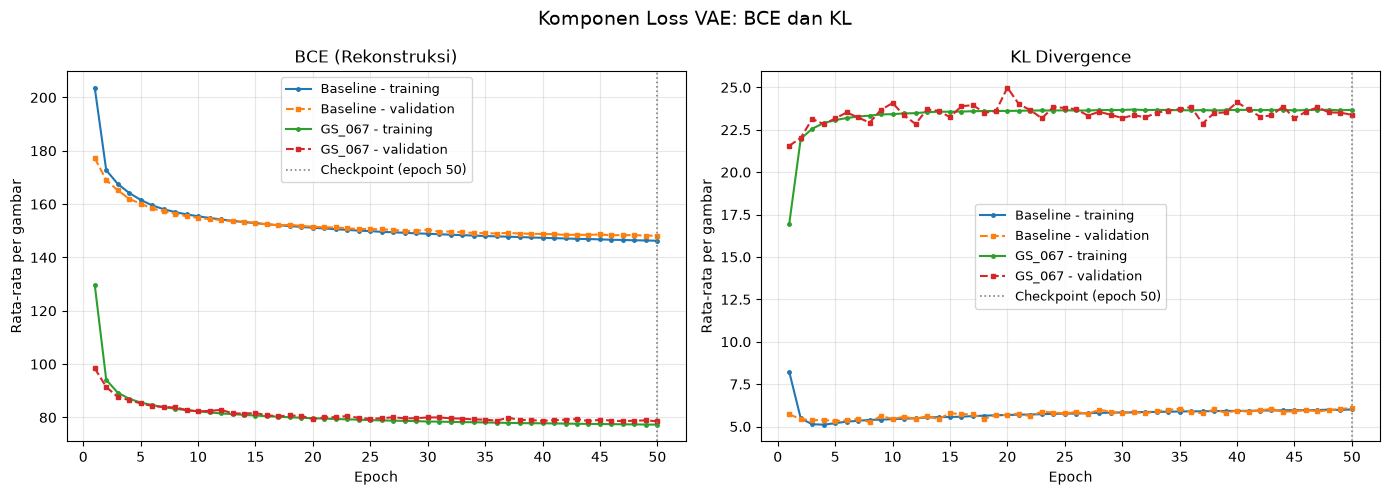

In [75]:
# Grafik Komponen BCE dan KL: Baseline dan Model Terbaik

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Setiap garis memiliki warna berbeda; garis putus-putus menandai data validation
line_styles = [
    ("Baseline", baseline_history_df, "train", "tab:blue", "-"),
    ("Baseline", baseline_history_df, "val", "tab:orange", "--"),
    (BEST_ID, best_history_df, "train", "tab:green", "-"),
    (BEST_ID, best_history_df, "val", "tab:red", "--"),
]
split_names = {"train": "training", "val": "validation"}
components = [("bce", "BCE (Rekonstruksi)"), ("kl", "KL Divergence")]

for ax, (key, label) in zip(axes, components):
    for model_name, history, split, color, linestyle in line_styles:
        ax.plot(history["epoch"], history[f"{split}_{key}"], color=color,
                linestyle=linestyle, marker="o" if split == "train" else "s",
                markersize=2.5, label=f"{model_name} - {split_names[split]}")

    # Tandai epoch checkpoint yang digunakan
    for checkpoint_epoch in sorted({BASELINE_EPOCH, BEST_EPOCH}):
        ax.axvline(checkpoint_epoch, color="gray", linestyle=":", linewidth=1.2,
                   label=f"Checkpoint (epoch {checkpoint_epoch})")

    ax.set_title(label)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Rata-rata per gambar")
    ax.set_xticks(range(0, len(best_history_df) + 1, 5))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9)

fig.suptitle("Komponen Loss VAE: BCE dan KL", fontsize=14)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "bce_kl_components.png", dpi=150)
plt.show()

### Analisis Komponen BCE dan KL

Pada baseline, penurunan total *loss* hampir seluruhnya berasal dari BCE. Training BCE turun dari 203,69 menjadi 146,26 dan validation BCE dari 177,25 menjadi 148,17. Training KL turun dari 8,22 menjadi 5,11 pada epoch 4, kemudian meningkat perlahan hingga 6,01 pada epoch 50, sedangkan validation KL berada pada kisaran 5,27–6,09. Kenaikan KL yang perlahan ini menunjukkan bahwa model secara bertahap menyimpan sedikit lebih banyak informasi di ruang laten, tetapi kapasitasnya tetap terbatas karena latent dimension hanya 2.

Pada GS_067, training BCE turun dari 129,73 menjadi 77,30 (turun 40,4%) dan validation BCE dari 98,44 menjadi 78,56. Sebaliknya, training KL naik cepat dari 16,96 menjadi 23,07 pada lima epoch pertama, lalu relatif stabil di kisaran 23,4–23,7 hingga epoch 50. Validation KL berfluktuasi pada kisaran 21,56–24,99. Pola ini menunjukkan bahwa pada awal training model dengan cepat mulai memanfaatkan latent space 16 dimensi untuk menyimpan informasi gambar, sehingga KL meningkat. Setelah itu KL cenderung stabil, sedangkan BCE terus menurun. Artinya, perbaikan pada epoch-epoch selanjutnya terutama berasal dari kemampuan decoder merekonstruksi gambar dengan lebih baik, bukan dari penambahan informasi laten.

Pada checkpoint yang digunakan, baseline memiliki validation BCE 148,17 dan validation KL 6,09, sedangkan GS_067 memiliki validation BCE 78,56 dan validation KL 23,38. KL GS_067 sekitar 3,8 kali lebih besar, tetapi BCE-nya hampir setengah dari baseline, sehingga total *loss* GS_067 jauh lebih rendah. Hal ini menegaskan bahwa KL yang kecil belum tentu menandakan model yang lebih baik; model terbaik adalah yang menyeimbangkan kualitas rekonstruksi (BCE) dan keteraturan ruang laten (KL).

### A.3. Analisis 72 Kombinasi Hyperparameter

*Grid search* dilakukan dengan menguji seluruh kombinasi dari empat *hyperparameter* berikut, sehingga diperoleh 3 × 4 × 2 × 3 = 72 kombinasi:

| Hyperparameter | Nilai yang diuji |
|---|---|
| Hidden dimension | 128, 256, 512 |
| Latent dimension | 2, 4, 8, 16 |
| Batch size | 64, 128 |
| Learning rate | 0,0001; 0,001; 0,005 |

Setiap kombinasi dilatih selama 10 epoch dengan *seed* 42 dan $\beta = 1$. Untuk setiap kombinasi dicatat **best validation loss**, yaitu validation loss terendah selama 10 epoch, beserta komponen BCE, KL, dan epoch tercapainya nilai tersebut.

Analisis dilakukan dalam dua tahap:

1. **Peringkat dan ringkasan**: sepuluh konfigurasi terbaik serta ringkasan validation loss untuk setiap nilai *hyperparameter*, untuk melihat pola umum dari seluruh kombinasi.
2. **Perbandingan terkontrol**: satu *hyperparameter* diubah, sementara tiga lainnya disamakan dengan konfigurasi terbaik grid search (GS_067). Dengan cara ini, perubahan *loss* dapat dikaitkan dengan *hyperparameter* yang diubah. Grafik batang bertumpuk menampilkan total *loss* sebagai jumlah BCE (bagian bawah) dan KL (bagian atas).

In [67]:
# Tabel Konfigurasi Terbaik dan Ringkasan per Hyperparameter

grid_summary = pd.read_csv("results/grid_search/grid_search_summary.csv")
completed = grid_summary[grid_summary["status"] == "completed"].copy()
print(f"Kombinasi selesai: {len(completed)} dari {len(grid_summary)}")

with open("results/grid_search/best_combination.json", encoding="utf-8") as f:
    best_combination = json.load(f)

table_columns = [
    "config_id", "hidden_dim", "latent_dim", "batch_size", "learning_rate",
    "best_val_loss", "best_val_bce", "best_val_kl", "best_val_epoch",
]

# 10 konfigurasi dengan validation loss terendah
top10 = completed.sort_values("best_val_loss").head(10)[table_columns].reset_index(drop=True)
top10.index = top10.index + 1  # peringkat dimulai dari 1

print("\n=== 10 Konfigurasi Terbaik (Grid Search, 10 Epoch) ===")
display(top10.round(4))

# Ringkasan validation loss untuk setiap nilai hyperparameter
for param in ["learning_rate", "latent_dim", "hidden_dim", "batch_size"]:
    param_summary = (
        completed.groupby(param)["best_val_loss"]
        .agg(jumlah="count", terbaik="min", median="median", terburuk="max")
        .sort_index()
    )
    print(f"\n=== Ringkasan per {param} ===")
    display(param_summary.round(3))
    param_summary.to_csv(EVAL_DIR / f"grid_search_per_{param}.csv")

# Berapa kombinasi yang mencapai val loss terbaik di epoch terakhir?
n_last_epoch = (completed["best_val_epoch"] == completed["epochs"]).sum()
print(f"\nKombinasi dengan val loss terbaik di epoch terakhir: {n_last_epoch} dari {len(completed)}")

top10.to_csv(EVAL_DIR / "grid_search_top10.csv", index_label="peringkat")

Kombinasi selesai: 72 dari 72

=== 10 Konfigurasi Terbaik (Grid Search, 10 Epoch) ===


,config_id,hidden_dim,latent_dim,batch_size,learning_rate,best_val_loss,best_val_bce,best_val_kl,best_val_epoch
1,GS_067,512,16,64,0.001,106.3336,82.2592,24.0744,10
2,GS_070,512,16,128,0.001,106.6508,83.2876,23.3632,10
3,GS_071,512,16,128,0.005,107.0829,84.1715,22.9114,9
4,GS_043,256,16,64,0.001,108.0655,84.8383,23.2272,10
5,GS_047,256,16,128,0.005,108.4517,85.5437,22.9080,9
6,GS_068,512,16,64,0.005,109.0802,86.8646,22.2156,9
7,GS_046,256,16,128,0.001,109.2529,85.9357,23.3172,10
8,GS_044,256,16,64,0.005,109.5087,87.3115,22.1972,10
9,GS_019,128,16,64,0.001,111.5581,88.9518,22.6064,10
10,GS_023,128,16,128,0.005,112.0992,90.7264,21.3728,10



=== Ringkasan per learning_rate ===


,jumlah,terbaik,median,terburuk
learning_rate,,,,
0.0001,24,114.873,142.005,177.341
0.0010,24,106.334,126.375,160.405
0.0050,24,107.083,124.722,154.710



=== Ringkasan per latent_dim ===


...


=== Ringkasan per hidden_dim ===


,jumlah,terbaik,median,terburuk
hidden_dim,,,,
128,24,111.558,135.323,177.341
256,24,108.065,132.801,172.026
512,24,106.334,129.006,166.392



=== Ringkasan per batch_size ===


,jumlah,terbaik,median,terburuk
batch_size,,,,
64,36,106.334,131.628,170.391
128,36,106.651,132.967,177.341



Kombinasi dengan val loss terbaik di epoch terakhir: 64 dari 72


Konfigurasi acuan (GS_067): {'hidden_dim': 512, 'latent_dim': 16, 'batch_size': 64, 'learning_rate': 0.001}

=== Pengaruh latent_dim | tetap: {'hidden_dim': 512, 'batch_size': 64, 'learning_rate': 0.001} ===


,config_id,latent_dim,best_val_loss,best_val_bce,best_val_kl,best_val_epoch
0,GS_049,2,152.0839,146.2077,5.8762,10
1,GS_055,4,130.8578,121.2413,9.6165,10
2,GS_061,8,113.3150,96.9708,16.3441,10
3,GS_067,16,106.3336,82.2592,24.0744,10



=== Pengaruh hidden_dim | tetap: {'latent_dim': 16, 'batch_size': 64, 'learning_rate': 0.001} ===


,config_id,hidden_dim,best_val_loss,best_val_bce,best_val_kl,best_val_epoch
0,GS_019,128,111.5581,88.9518,22.6064,10
1,GS_043,256,108.0655,84.8383,23.2272,10
2,GS_067,512,106.3336,82.2592,24.0744,10



=== Pengaruh batch_size | tetap: {'hidden_dim': 512, 'latent_dim': 16, 'learning_rate': 0.001} ===


,config_id,batch_size,best_val_loss,best_val_bce,best_val_kl,best_val_epoch
0,GS_067,64,106.3336,82.2592,24.0744,10
1,GS_070,128,106.6508,83.2876,23.3632,10



=== Pengaruh learning_rate | tetap: {'hidden_dim': 512, 'latent_dim': 16, 'batch_size': 64} ===


,config_id,learning_rate,best_val_loss,best_val_bce,best_val_kl,best_val_epoch
0,GS_069,0.0001,114.8733,92.2424,22.6309,10
1,GS_067,0.0010,106.3336,82.2592,24.0744,10
2,GS_068,0.0050,109.0802,86.8646,22.2156,9


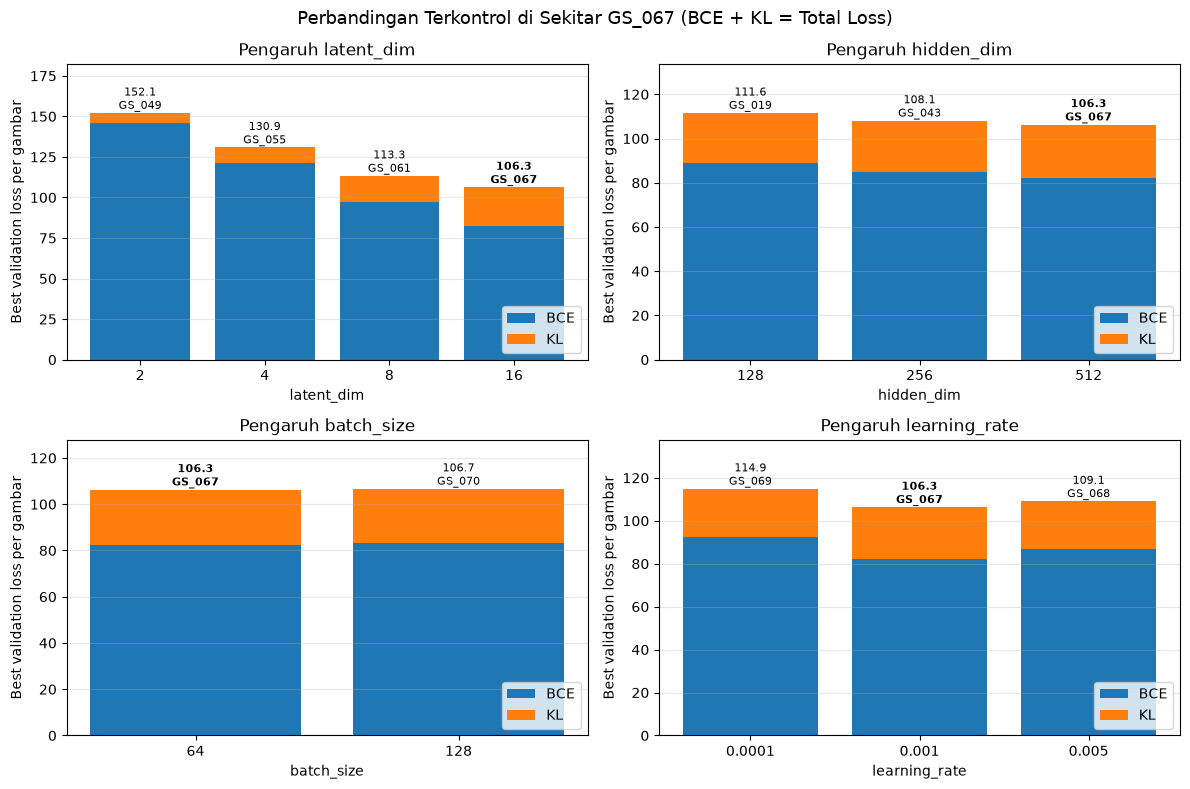

In [68]:
# Perbandingan Terkontrol Hyperparameter di Sekitar Konfigurasi Terbaik

# Konfigurasi terbaik grid search digunakan sebagai acuan
GRID_BEST_ID = best_combination["config_id"]
reference = {
    key: best_combination["config"][key]
    for key in ["hidden_dim", "latent_dim", "batch_size", "learning_rate"]
}
print(f"Konfigurasi acuan ({GRID_BEST_ID}):", reference)


def controlled_comparison(df, vary, reference):
    """Mengambil kombinasi yang hanya berbeda pada hyperparameter `vary`."""
    mask = np.ones(len(df), dtype=bool)
    for key, value in reference.items():
        if key != vary:
            mask &= np.isclose(df[key].astype(float), float(value))

    columns = ["config_id", vary, "best_val_loss", "best_val_bce", "best_val_kl", "best_val_epoch"]
    return df.loc[mask, columns].sort_values(vary).reset_index(drop=True)


comparisons = {}
for vary in ["latent_dim", "hidden_dim", "batch_size", "learning_rate"]:
    comparisons[vary] = controlled_comparison(completed, vary, reference)
    fixed = {k: v for k, v in reference.items() if k != vary}

    print(f"\n=== Pengaruh {vary} | tetap: {fixed} ===")
    display(comparisons[vary].round(4))
    comparisons[vary].to_csv(EVAL_DIR / f"controlled_{vary}.csv", index=False)

# Grafik batang bertumpuk: BCE + KL = total loss
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (vary, table) in zip(axes.flat, comparisons.items()):
    x = np.arange(len(table))
    ax.bar(x, table["best_val_bce"], label="BCE")
    ax.bar(x, table["best_val_kl"], bottom=table["best_val_bce"], label="KL")

    # Tulis total loss dan ID konfigurasi di atas setiap batang
    for i, (total, config_id) in enumerate(zip(table["best_val_loss"], table["config_id"])):
        ax.text(i, total, f"{total:.1f}\n{config_id}", ha="center", va="bottom", fontsize=8,
                fontweight="bold" if config_id == GRID_BEST_ID else "normal")

    ax.set_xticks(x)
    ax.set_xticklabels([str(v) for v in table[vary]])
    ax.set_xlabel(vary)
    ax.set_ylabel("Best validation loss per gambar")
    ax.set_title(f"Pengaruh {vary}")
    ax.margins(y=0.2)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(loc="lower right")

fig.suptitle(f"Perbandingan Terkontrol di Sekitar {GRID_BEST_ID} (BCE + KL = Total Loss)", fontsize=13)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "grid_search_controlled.png", dpi=150)
plt.show()

### Analisis Hasil Grid Search

Seluruh 72 kombinasi berhasil diselesaikan. Konfigurasi dengan validation loss terendah adalah GS_067 (hidden dimension 512, latent dimension 16, batch size 64, learning rate 0,001) dengan validation loss 106,33 pada epoch 10. Selisihnya dengan peringkat kedua, GS_070, hanya 0,32, sehingga keunggulannya pada tahap ini tergolong tipis.

Seluruh sepuluh konfigurasi teratas menggunakan latent dimension 16. Ringkasan per *hyperparameter* menunjukkan bahwa latent dimension memiliki pengaruh paling besar: median validation loss turun dari 155,71 (latent 2) menjadi 134,73 (latent 4), 118,26 (latent 8), dan 111,83 (latent 16). Learning rate 0,0001 menghasilkan median terburuk (142,00), karena langkah pembaruan bobot yang sangat kecil membuat model belum cukup belajar dalam 10 epoch. Learning rate 0,001 menghasilkan nilai terbaik (106,33), sedangkan 0,005 memiliki median sedikit lebih baik (124,72 vs 126,38). Hidden dimension dan batch size memberikan perbedaan median yang jauh lebih kecil.

Perbandingan terkontrol di sekitar GS_067 menunjukkan:

- **Latent dimension**: validation loss turun dari 152,08 (latent 2) menjadi 130,86 (latent 4), 113,32 (latent 8), dan 106,33 (latent 16). BCE turun dari 146,21 menjadi 82,26, sedangkan KL naik dari 5,88 menjadi 24,07. Latent space yang lebih besar memungkinkan model menyimpan lebih banyak detail gambar.
- **Hidden dimension**: validation loss turun dari 111,56 (128) menjadi 108,07 (256) dan 106,33 (512). Pengaruhnya konsisten tetapi jauh lebih kecil daripada latent dimension.
- **Batch size**: batch 64 menghasilkan 106,33 dan batch 128 menghasilkan 106,65. Selisih 0,32 ini sangat kecil.
- **Learning rate**: 0,0001 menghasilkan 114,87, 0,001 menghasilkan 106,33, dan 0,005 menghasilkan 109,08. Learning rate 0,001 memberikan keseimbangan terbaik antara kecepatan dan kestabilan belajar.

Sebanyak 64 dari 72 kombinasi mencapai validation loss terbaik tepat pada epoch ke-10. Artinya, sebagian besar model masih terus membaik ketika training dihentikan, sehingga 10 epoch belum cukup untuk mencapai konvergensi. Oleh karena itu, lima kombinasi terbaik dilatih ulang hingga maksimal 50 epoch dengan *early stopping* (patience 5). Setelah training ulang, GS_067 tetap memiliki validation loss terendah, yaitu 101,94 pada epoch 50 (sebelumnya 106,33 pada grid search), diikuti GS_070 dengan 102,28. Dengan demikian, GS_067 hasil training ulang dipilih sebagai model terbaik dan digunakan pada analisis A.1–A.2 serta evaluasi test pada bagian B.

Sebagai catatan, konfigurasi GS_068 (hidden 512, latent 16, batch 64, learning rate 0,005) identik dengan konfigurasi terbaik pada eksperimen sebelumnya dan menghasilkan validation loss yang sama persis (109,080196). Hal ini menunjukkan bahwa eksperimen dapat direproduksi dengan *seed* yang sama.

## B. Evaluasi Test Set dan Perbandingan Rekonstruksi

Bagian ini menilai kinerja akhir model pada data yang sama sekali tidak digunakan selama pengembangan. Pembagian data pada proyek ini adalah sebagai berikut:

| Subset | Jumlah gambar | Kegunaan |
|---|---:|---|
| Training | 54.000 | Memperbarui bobot model |
| Validation | 6.000 | Memilih *checkpoint*, konfigurasi *hyperparameter*, dan model akhir |
| Test | 10.000 | Menilai kinerja akhir model yang telah dipilih |

Karena data validasi telah digunakan berulang kali untuk memilih model, nilai validation loss berpotensi sedikit bias ke arah optimis. Data test memberikan penilaian yang lebih objektif terhadap kemampuan model pada data baru.

### B.1. Persiapan Evaluasi

Model yang dievaluasi adalah baseline (bobot epoch 50) dan GS_067 hasil training ulang (bobot epoch 50), yang dimuat pada sel Load Checkpoint Baseline dan GS_067. Evaluasi dilakukan dengan ketentuan berikut:

- Model berada dalam mode evaluasi (`model.eval()`) dan perhitungan dilakukan di dalam `torch.no_grad()`, sehingga bobot tidak berubah dan gradien tidak dihitung.
- Seluruh gambar berasal dari `test_loader`, yang memuat 10.000 gambar test resmi MNIST tanpa pengacakan, dengan *preprocessing* yang sama untuk kedua model.
- Pada `forward()`, VAE membentuk vektor laten melalui *reparameterization trick* $z = \mu + \sigma \odot \epsilon$ dengan $\epsilon \sim \mathcal{N}(0, I)$. Proses ini tetap bersifat acak meskipun model berada dalam mode evaluasi. Oleh karena itu, *seed* evaluasi ditetapkan sebesar 42 dan diatur ulang sebelum setiap model dievaluasi agar hasil dapat direproduksi dan kedua model memperoleh urutan bilangan acak yang sama.

In [69]:
# Persiapan Evaluasi Test Set

import torch
import torch.nn.functional as F

EVAL_SEED = 42


def set_eval_seed(seed=EVAL_SEED):
    """Mengatur seed agar sampling laten pada VAE dapat diulang."""
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# Daftar model yang dibandingkan beserta beta, epoch, dan validation loss-nya
models_to_eval = {
    "Baseline": {
        "model": vae_baseline,
        "beta": float(baseline_config_json["beta"]),
        "epoch": BASELINE_EPOCH,
        "val_loss": float(baseline_history_df.loc[
            baseline_history_df["epoch"] == BASELINE_EPOCH, "val_loss"].iloc[0]),
    },
    BEST_ID: {
        "model": vae_best,
        "beta": float(best_model_config["beta"]),
        "epoch": BEST_EPOCH,
        "val_loss": float(best_history_df.loc[
            best_history_df["epoch"] == BEST_EPOCH, "val_loss"].iloc[0]),
    },
}

# Memastikan vae_best sesuai dengan konfigurasi model terbaik
assert vae_best.hidden_dim == best_model_config["hidden_dim"]
assert vae_best.latent_dim == best_model_config["latent_dim"]

# Memastikan test_loader berisi 10.000 gambar test resmi
assert test_loader.dataset is test_dataset
n_test_images = sum(batch.shape[0] for batch in test_loader)
assert n_test_images == 10000, f"Jumlah gambar test: {n_test_images}"

# Memastikan kedua model dalam mode evaluasi
for name, info in models_to_eval.items():
    info["model"].eval()
    assert not info["model"].training, f"{name} masih dalam mode training"

print(f"Jumlah gambar test : {n_test_images:,}")
print(f"Jumlah batch test  : {len(test_loader)}")
print(f"Seed evaluasi      : {EVAL_SEED}")
for name, info in models_to_eval.items():
    model = info["model"]
    print(f"{name:9s}: hidden={model.hidden_dim}, latent={model.latent_dim}, "
          f"beta={info['beta']}, bobot epoch {info['epoch']}")

Jumlah gambar test : 10,000
Jumlah batch test  : 79
Seed evaluasi      : 42
Baseline : hidden=128, latent=2, beta=1.0, bobot epoch 50
GS_067   : hidden=512, latent=16, beta=1.0, bobot epoch 50


### B.2. Metrik pada Seluruh Test Set

Tiga metrik dihitung untuk setiap model:

| Metrik | Makna |
|---|---|
| **BCE/gambar** | Besarnya kesalahan rekonstruksi rata-rata per gambar |
| **KL/gambar** | Besarnya komponen regularisasi distribusi laten rata-rata per gambar |
| **Total loss/gambar** | Gabungan keduanya, $\text{BCE} + \beta \cdot D_{KL}$ |

Seluruh metrik dilaporkan sebagai rata-rata per gambar atas 10.000 gambar test, bukan hasil satu *batch*. Data test terbagi menjadi 79 *batch*: 78 *batch* berisi 128 gambar dan *batch* terakhir berisi 16 gambar. Karena ukuran *batch* tidak sama, rata-rata akhir dihitung dengan pembobotan jumlah gambar:

$$\bar{L} = \frac{\sum_{b=1}^{79} n_b \cdot \bar{L}_b}{\sum_{b=1}^{79} n_b}$$

dengan $n_b$ adalah jumlah gambar pada *batch* ke-$b$ dan $\bar{L}_b$ adalah rata-rata *loss* pada *batch* tersebut. Perhitungan ini telah diterapkan pada fungsi `evaluate_vae` (Cell 17).

Hasil test juga dibandingkan dengan validation loss masing-masing model untuk menilai konsistensi kinerja pada data yang belum pernah digunakan. Selain itu, evaluasi diulang dengan lima *seed* berbeda untuk memastikan bahwa perbedaan kedua model bukan disebabkan oleh keacakan *sampling* laten.

In [70]:
# Evaluasi BCE, KL, dan Total Loss pada Test Set

test_rows = []
for name, info in models_to_eval.items():
    set_eval_seed(EVAL_SEED)
    metrics = evaluate_vae(info["model"], test_loader, device, beta=info["beta"])

    # Memastikan total loss = BCE + beta x KL
    assert np.isclose(metrics["loss"], metrics["bce"] + info["beta"] * metrics["kl"], rtol=1e-4)

    test_rows.append({
        "Model": name,
        "Bobot epoch": info["epoch"],
        "Jumlah gambar": n_test_images,
        "BCE/gambar": metrics["bce"],
        "KL/gambar": metrics["kl"],
        "Total loss/gambar": metrics["loss"],
        "Validation loss": info["val_loss"],
    })

test_results = pd.DataFrame(test_rows)
test_results["Selisih test - validation"] = (
    test_results["Total loss/gambar"] - test_results["Validation loss"]
)

print(f"=== Hasil Evaluasi Test Set (seed {EVAL_SEED}) ===")
display(test_results.round(4))

test_results.to_csv(EVAL_DIR / "test_metrics.csv", index=False)

=== Hasil Evaluasi Test Set (seed 42) ===


,Model,Bobot epoch,Jumlah gambar,BCE/gambar,KL/gambar,Total loss/gambar,Validation loss,Selisih test - validation
0,Baseline,50,10000,148.4550,6.0206,154.4757,154.2543,0.2213
1,GS_067,50,10000,78.1494,23.3842,101.5336,101.9419,-0.4083


In [71]:
# Pemeriksaan Kestabilan Hasil Test terhadap Seed

stability_rows = []
for name, info in models_to_eval.items():
    for seed in [0, 1, 2, 3, 4]:
        set_eval_seed(seed)
        metrics = evaluate_vae(info["model"], test_loader, device, beta=info["beta"])
        stability_rows.append({"Model": name, "seed": seed, **metrics})

stability = pd.DataFrame(stability_rows)

print("=== Rata-rata dan Simpangan Baku dari 5 Seed ===")
display(stability.groupby("Model")[["loss", "bce", "kl"]].agg(["mean", "std"]).round(4))

stability.to_csv(EVAL_DIR / "test_metrics_seed_stability.csv", index=False)

=== Rata-rata dan Simpangan Baku dari 5 Seed ===


loss               bce               kl     
              mean     std      mean     std     mean  std
Model                                                     
Baseline  154.5365  0.0384  148.5158  0.0384   6.0206  0.0
GS_067    101.4633  0.0655   78.0791  0.0655  23.3842  0.0

### Analisis Metrik Test

Pada 10.000 gambar test, GS_067 menghasilkan total *loss* sebesar 101,53 per gambar, sedangkan baseline sebesar 154,48 per gambar. Total *loss* GS_067 lebih rendah 52,94 atau sekitar 34,3% dibandingkan baseline. Perbedaan ini menunjukkan bahwa GS_067 memberikan keseimbangan yang lebih baik antara kualitas rekonstruksi dan regularisasi ruang laten berdasarkan fungsi *loss* yang digunakan. BCE GS_067 sebesar 78,15, lebih rendah daripada baseline sebesar 148,46. Sebaliknya, KL GS_067 lebih tinggi, yaitu 23,38 dibandingkan 6,02 pada baseline. Peningkatan KL tersebut menunjukkan kontribusi regularisasi yang lebih besar, tetapi diimbangi oleh penurunan BCE yang lebih besar sehingga total *loss* GS_067 tetap lebih rendah. Hasil ini konsisten dengan evaluasi validasi dan menunjukkan bahwa konfigurasi GS_067 mampu merekonstruksi gambar test dengan kesalahan piksel yang lebih rendah.

*Test loss* kedua model relatif dekat dengan *validation loss*-nya. Baseline memiliki *test loss* 154,48, sekitar 0,22 lebih tinggi daripada *validation loss* 154,25. Pada GS_067, *test loss* sebesar 101,53, sekitar 0,41 lebih rendah daripada *validation loss* 101,94. Kedekatan nilai tersebut menunjukkan bahwa tidak terlihat perbedaan performa yang besar antara data validasi dan data test pada evaluasi ini. Namun, selisih yang kecil saja belum cukup untuk membuktikan bahwa model sepenuhnya bebas dari *overfitting*.

Evaluasi dengan lima *seed* sampling laten (0–4), menggunakan checkpoint yang sama, menghasilkan rata-rata total *loss* 154,54 dengan simpangan baku 0,04 pada baseline dan 101,46 dengan simpangan baku 0,07 pada GS_067. Simpangan baku yang relatif kecil menunjukkan bahwa variasi hasil evaluasi akibat sampling laten pada kedua checkpoint tersebut kecil dibandingkan perbedaan rata-rata *loss* kedua model. Nilai KL memiliki simpangan baku 0,00 pada presisi empat desimal karena KL dihitung langsung dari parameter distribusi laten, yaitu μ dan log-variance, yang ditentukan oleh input dan bobot model. Sebaliknya, BCE dapat berubah karena vektor laten yang disampling memengaruhi hasil rekonstruksi. Perlu ditegaskan bahwa pengujian ini mengukur variasi hasil evaluasi akibat sampling laten pada model yang sudah dilatih, bukan kestabilan proses training ketika menggunakan *seed* training yang berbeda.

Secara keseluruhan, hasil test mendukung pemilihan GS_067 sebagai model dengan total *loss* lebih rendah dibandingkan baseline pada dataset dan konfigurasi eksperimen ini. Kesimpulan tersebut didukung oleh BCE yang lebih rendah, hasil validasi yang konsisten, dan pengamatan variasi evaluasi pada lima *seed*.

### B.3. Perbandingan Rekonstruksi pada Sampel Tetap

Evaluasi numerik dilengkapi dengan pengamatan visual terhadap hasil rekonstruksi. Sepuluh gambar test dipilih dengan indeks tetap, yaitu kemunculan pertama setiap digit 0 hingga 9 pada test set. Pemilihan ini memastikan setiap digit terwakili dan sampel yang sama dapat digunakan kembali setiap kali notebook dijalankan.

Gambar disusun dalam tiga baris:

1. Gambar asli
2. Rekonstruksi baseline
3. Rekonstruksi model terbaik

Setiap kolom menampilkan gambar sumber yang sama, sehingga hasil kedua model dapat dibandingkan secara langsung. Seluruh gambar ditampilkan dengan skala *grayscale* yang sama (0–1), dan rekonstruksi dihasilkan dengan *seed* evaluasi yang sama. Angka di bawah setiap rekonstruksi menunjukkan BCE gambar tersebut, sehingga pengamatan visual dapat dikaitkan dengan nilai numeriknya.

Indeks test yang digunakan: [3, 2, 1, 18, 4, 8, 11, 0, 61, 7]


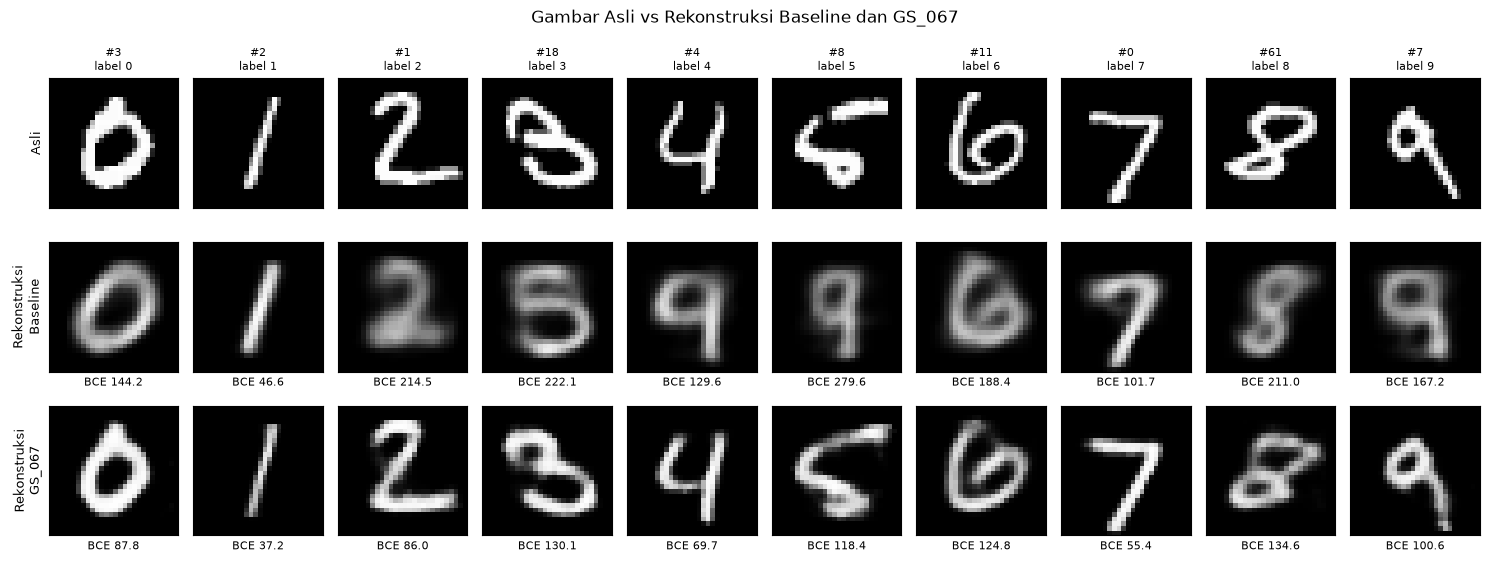

In [72]:
# Perbandingan Gambar Asli dan Rekonstruksi Kedua Model

labels_test = np.asarray(y_test)

# Indeks pertama untuk setiap digit 0-9 pada test set
fixed_indices = [int(np.flatnonzero(labels_test == digit)[0]) for digit in range(10)]
print("Indeks test yang digunakan:", fixed_indices)


def reconstruct(model, images, seed=EVAL_SEED):
    """Merekonstruksi gambar dengan seed tetap tanpa menghitung gradien."""
    model.eval()
    set_eval_seed(seed)
    with torch.no_grad():
        reconstruction, _, _ = model(images)
    return reconstruction


def bce_per_image(reconstruction, images):
    """Menghitung BCE untuk setiap gambar (jumlah 784 piksel)."""
    return F.binary_cross_entropy(reconstruction, images, reduction="none").flatten(1).sum(1)


def plot_reconstruction(indices, title, save_path):
    """Baris 1: asli, baris 2-3: rekonstruksi. Setiap kolom adalah gambar yang sama."""
    originals = torch.stack([test_dataset[i] for i in indices]).to(device)

    rows = [("Asli", originals, None)]
    for name, info in models_to_eval.items():
        reconstruction = reconstruct(info["model"], originals)
        rows.append((f"Rekonstruksi\n{name}", reconstruction,
                     bce_per_image(reconstruction, originals)))

    n_cols = len(indices)
    fig, axes = plt.subplots(len(rows), n_cols, figsize=(1.5 * n_cols, 1.9 * len(rows)))

    for r, (row_name, images, bces) in enumerate(rows):
        for c in range(n_cols):
            ax = axes[r, c]
            ax.imshow(images[c, 0].cpu().numpy(), cmap="gray", vmin=0, vmax=1)
            ax.set_xticks([])
            ax.set_yticks([])
            if r == 0:
                ax.set_title(f"#{indices[c]}\nlabel {labels_test[indices[c]]}", fontsize=8)
            if bces is not None:
                ax.set_xlabel(f"BCE {bces[c].item():.1f}", fontsize=8)
        axes[r, 0].set_ylabel(row_name, fontsize=9)

    fig.suptitle(title, fontsize=12)
    fig.tight_layout()
    fig.savefig(save_path, dpi=150)
    plt.show()


plot_reconstruction(
    fixed_indices,
    f"Gambar Asli vs Rekonstruksi Baseline dan {BEST_ID}",
    FIGURE_DIR / "reconstruction_fixed_samples.png",
)

### B.4. Contoh Keberhasilan, Kegagalan, dan Digit Tersulit

Sampel tetap pada B.3 hanya mewakili sepuluh gambar. Untuk memperoleh gambaran yang lebih menyeluruh, BCE dihitung untuk setiap gambar pada seluruh 10.000 gambar test menggunakan kedua model. Hasil perhitungan tersebut digunakan untuk tiga analisis:

1. **Delapan rekonstruksi terburuk** menurut model terbaik, yaitu gambar dengan BCE tertinggi, sebagai contoh kegagalan model.
2. **Delapan rekonstruksi terbaik** menurut model terbaik, yaitu gambar dengan BCE terendah, sebagai contoh keberhasilan model.
3. **Rata-rata BCE per digit** untuk kedua model, untuk mengidentifikasi digit yang paling sulit dan paling mudah direkonstruksi.

Sebagai pemeriksaan konsistensi, rata-rata BCE per gambar dari perhitungan ini dibandingkan dengan nilai BCE/gambar pada B.2; keduanya harus sama karena menggunakan *seed* yang sama. Perlu dicatat bahwa BCE merupakan jumlah atas 784 piksel, sehingga digit dengan goresan lebih sedikit cenderung memiliki BCE yang lebih rendah.

Baseline : rata-rata BCE = 148.4550 (tabel B.2: 148.4550)
GS_067   : rata-rata BCE = 78.1494 (tabel B.2: 78.1494)


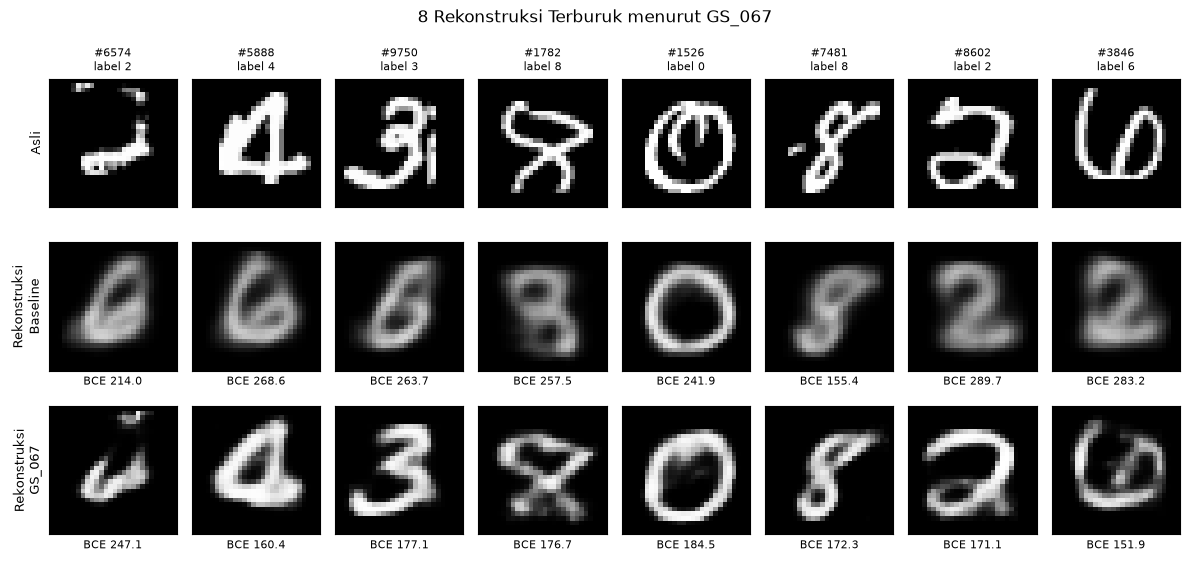

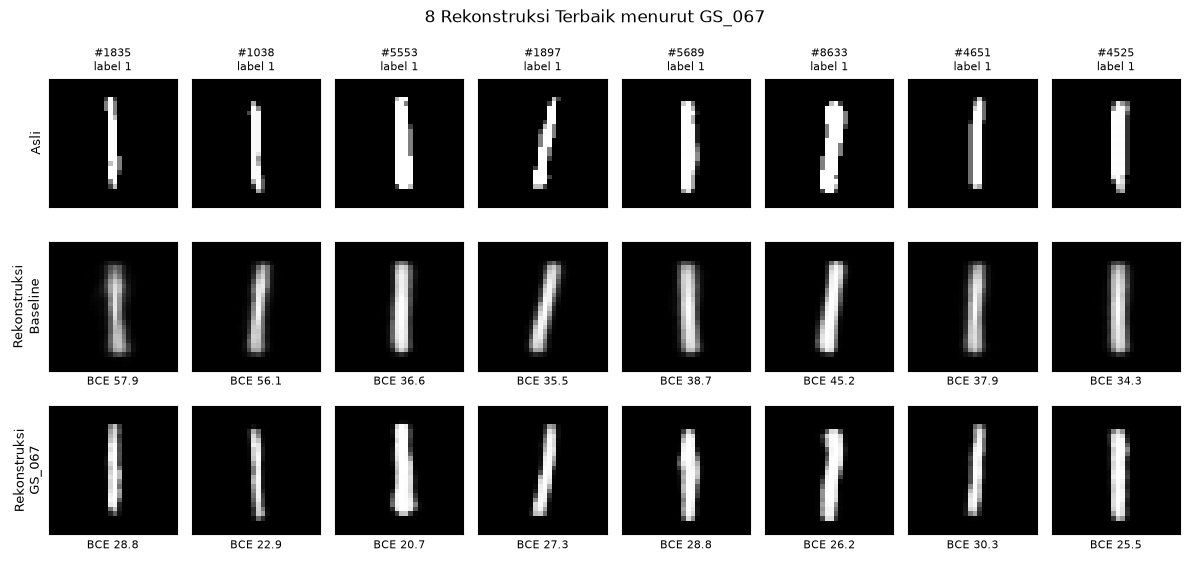


=== Rata-rata BCE per Digit ===


,BCE Baseline,BCE GS_067
label,,
0,168.24,88.39
1,59.14,40.15
2,190.93,92.03
3,165.37,85.95
4,147.15,77.43
5,177.25,87.89
6,164.59,81.14
7,123.91,66.79
8,172.66,95.56


In [73]:
# Rekonstruksi Terbaik, Terburuk, dan Rata-rata BCE per Digit


def per_image_bce_all(model, loader, seed=EVAL_SEED):
    """Menghitung BCE setiap gambar pada seluruh test set."""
    model.eval()
    set_eval_seed(seed)
    values = []
    with torch.no_grad():
        for images in loader:
            images = images.to(device)
            reconstruction, _, _ = model(images)
            values.append(bce_per_image(reconstruction, images).cpu())
    return torch.cat(values).numpy()


bce_all = {name: per_image_bce_all(info["model"], test_loader)
           for name, info in models_to_eval.items()}

# Rata-rata harus sama dengan BCE/gambar pada tabel B.2 (seed sama)
for name, values in bce_all.items():
    from_table = test_results.loc[test_results["Model"] == name, "BCE/gambar"].iloc[0]
    print(f"{name:9s}: rata-rata BCE = {values.mean():.4f} (tabel B.2: {from_table:.4f})")

# Urutkan gambar berdasarkan BCE model terbaik
order = np.argsort(bce_all[BEST_ID])
worst_indices = [int(i) for i in order[-8:][::-1]]
best_indices = [int(i) for i in order[:8]]

plot_reconstruction(worst_indices, f"8 Rekonstruksi Terburuk menurut {BEST_ID}",
                    FIGURE_DIR / "reconstruction_worst_best_model.png")
plot_reconstruction(best_indices, f"8 Rekonstruksi Terbaik menurut {BEST_ID}",
                    FIGURE_DIR / "reconstruction_best_best_model.png")

# Rata-rata BCE untuk setiap digit
per_digit = pd.DataFrame({"label": labels_test,
                          **{f"BCE {name}": values for name, values in bce_all.items()}})
per_digit = per_digit.groupby("label").mean().astype(float)

print("\n=== Rata-rata BCE per Digit ===")
display(per_digit.round(2))

per_digit.to_csv(EVAL_DIR / "test_bce_per_digit.csv")

### Analisis Rekonstruksi

Pada sepuluh sampel tetap, rekonstruksi GS_067 lebih mendekati gambar asli dibandingkan baseline, dan BCE GS_067 lebih rendah pada seluruh sampel. Contohnya, pada digit 2 BCE turun dari 214,5 menjadi 86,0, dan pada digit 5 dari 279,6 menjadi 118,4. Baseline, yang hanya memiliki latent dimension 2, menghasilkan gambar yang kabur dan pada beberapa sampel mengubah identitas digit: digit 4 dan 5 tampak menyerupai 9, sedangkan digit 3 tampak menyerupai 5. Sebaliknya, seluruh rekonstruksi GS_067 masih dapat dikenali sebagai digit aslinya, dengan bentuk goresan yang lebih tajam. Kekurangan yang masih terlihat adalah tepi goresan yang sedikit kabur serta bentuk digit 8 (indeks 61) yang tampak tercoreng, yang juga tercermin dari BCE-nya yang relatif tinggi (134,6).

Delapan rekonstruksi terburuk menurut GS_067 berasal dari digit 2 (dua sampel), 8 (dua sampel), 4, 3, 0, dan 6. Gambar aslinya memiliki bentuk yang tidak umum, misalnya goresan sangat tebal (indeks 5888), goresan tambahan di samping digit (indeks 9750), garis di dalam lingkaran digit 0 (indeks 1526), digit 2 yang terputus-putus (indeks 6574) atau memiliki lengkungan tambahan (indeks 8602), serta digit 8 dan 6 yang ditulis dengan gaya tidak lazim (indeks 1782, 7481, dan 3846). GS_067 cenderung merekonstruksi versi digit yang lebih umum: goresan tambahan pada indeks 9750 dan garis di dalam digit 0 pada indeks 1526 hilang, sehingga identitas digit tetap dikenali tetapi BCE-nya tinggi karena detail aslinya tidak terbawa. Pada sampel yang sama, baseline umumnya menghasilkan gumpalan kabur yang menyerupai digit lain. Menariknya, pada indeks 6574 BCE GS_067 (247,1) justru lebih tinggi daripada baseline (214,0). Hal ini menunjukkan bahwa rekonstruksi yang kabur dapat memperoleh BCE lebih rendah daripada rekonstruksi yang tajam tetapi posisi goresannya kurang tepat, sehingga BCE perlu dibaca bersama pengamatan visual.

Kedelapan rekonstruksi terbaik seluruhnya merupakan digit 1 dengan goresan tipis dan lurus, yang direkonstruksi hampir identik oleh GS_067 (BCE 20,7–30,3). Hal ini sejalan dengan rata-rata BCE per digit: digit 1 memiliki BCE terendah pada kedua model (59,14 pada baseline dan 40,15 pada GS_067), sedangkan digit dengan BCE tertinggi adalah 2 pada baseline (190,93) dan 8 pada GS_067 (95,56). Perlu dicatat bahwa BCE dijumlahkan atas 784 piksel, sehingga digit dengan goresan sedikit seperti angka 1 secara alami memiliki BCE lebih rendah. Oleh karena itu, perbandingan BCE antar-digit sebagian juga mencerminkan banyaknya piksel goresan, bukan semata-mata tingkat kesulitan bentuk.

Secara keseluruhan, hasil numerik dan visual saling mendukung: GS_067 memiliki test loss lebih rendah dan menghasilkan rekonstruksi yang lebih tajam serta lebih mudah dikenali. Keterbatasannya adalah hasil rekonstruksi masih sedikit kabur dan model kesulitan mempertahankan detail pada tulisan tangan yang tidak umum, yang merupakan keterbatasan umum VAE dengan decoder sederhana berbasis *fully connected layer*.